In [1]:
%pip install -q yfinance pandas numpy scikit-learn matplotlib seaborn
%pip install -q torch cvxpy "cvxpylayers[torch]"

import yfinance as yf
import pandas as pd
import numpy as np

assets = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

state_tickers = [
    "SPY",
    "^VIX"
]

all_tickers = assets + state_tickers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 41.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.2/254.2 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 81.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.8/72.8 kB 6.1 MB/s eta 0:00:00


In [2]:
from pathlib import Path

data_dirs = [Path("../data/raw"), Path("data/raw")]
data_dir = next((path for path in data_dirs if path.exists()), Path("data/raw"))
data_dir.mkdir(parents=True, exist_ok=True)
data_path = data_dir / "yahoo_market_data.csv"

data = yf.download(
    all_tickers,
    start="2010-01-01",
    end="2025-12-31",
    auto_adjust=False,
    progress=False
)

if data.empty:
    data = pd.read_csv(
        data_path,
        header=[0, 1],
        index_col=0,
        parse_dates=True
    )

if data.empty:
    raise RuntimeError(
        "Yahoo Finance returned no data and the cached market-data CSV is empty."
    )

print(data.shape)
print(data.head())
print(data.tail())

(4023, 66)
Price       Adj Close                                                       \
Ticker            SPY        XLB        XLE       XLF        XLI       XLK   
Date                                                                         
2010-01-04  84.368996  11.916906  17.043316  8.879747  20.815493  9.356692   
2010-01-05  84.592300  11.955440  17.182426  9.042953  20.889000  9.344632   
2010-01-06  84.651840  12.158608  17.388184  9.061089  20.933094  9.240092   
2010-01-07  85.009224  12.064033  17.362097  9.254518  21.160946  9.203899   
2010-01-08  85.292107  12.232168  17.475122  9.200116  21.499052  9.264212   

Price                                                  ...    Volume  \
Ticker            XLP       XLU        XLV        XLY  ...       XLB   
Date                                                   ...             
2010-01-04  17.019968  8.765263  23.788492  12.257142  ...  15135000   
2010-01-05  17.026352  8.660915  23.555201  12.302088  ...  17678400   
2010

In [3]:
if not data.empty:
    data_path.parent.mkdir(parents=True, exist_ok=True)
    data.to_csv(data_path)

In [4]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4023 entries, 2010-01-04 to 2025-12-30
Data columns (total 66 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, SPY)   4023 non-null   float64
 1   (Adj Close, XLB)   4023 non-null   float64
 2   (Adj Close, XLE)   4023 non-null   float64
 3   (Adj Close, XLF)   4023 non-null   float64
 4   (Adj Close, XLI)   4023 non-null   float64
 5   (Adj Close, XLK)   4023 non-null   float64
 6   (Adj Close, XLP)   4023 non-null   float64
 7   (Adj Close, XLU)   4023 non-null   float64
 8   (Adj Close, XLV)   4023 non-null   float64
 9   (Adj Close, XLY)   4023 non-null   float64
 10  (Adj Close, ^VIX)  4023 non-null   float64
 11  (Close, SPY)       4023 non-null   float64
 12  (Close, XLB)       4023 non-null   float64
 13  (Close, XLE)       4023 non-null   float64
 14  (Close, XLF)       4023 non-null   float64
 15  (Close, XLI)       4023 non-null   float64
 16  (Close

In [5]:
print(data.isnull().sum())

Price      Ticker
Adj Close  SPY       0
           XLB       0
           XLE       0
           XLF       0
           XLI       0
                    ..
Volume     XLP       0
           XLU       0
           XLV       0
           XLY       0
           ^VIX      0
Length: 66, dtype: int64


In [6]:
print(data.index.min())
print(data.index.max())

2010-01-04 00:00:00
2025-12-30 00:00:00


In [7]:
import pandas as pd
import yfinance as yf

if "data" not in globals() or data.empty:
    try:
        data = pd.read_csv(data_path, header=[0, 1], index_col=0, parse_dates=True)
    except FileNotFoundError:
        assets = [
            "XLB", "XLE", "XLF",
            "XLI", "XLK", "XLP",
            "XLU", "XLV", "XLY"
        ]

        state_tickers = [
            "SPY",
            "^VIX"
        ]

        all_tickers = assets + state_tickers
        data = yf.download(
            all_tickers,
            start="2010-01-01",
            end="2025-12-31",
            auto_adjust=False,
            progress=False
        )

    if data.empty:
        raise RuntimeError("No market data is available.")

print(data.columns)

MultiIndex([('Adj Close',  'SPY'),
            ('Adj Close',  'XLB'),
            ('Adj Close',  'XLE'),
            ('Adj Close',  'XLF'),
            ('Adj Close',  'XLI'),
            ('Adj Close',  'XLK'),
            ('Adj Close',  'XLP'),
            ('Adj Close',  'XLU'),
            ('Adj Close',  'XLV'),
            ('Adj Close',  'XLY'),
            ('Adj Close', '^VIX'),
            (    'Close',  'SPY'),
            (    'Close',  'XLB'),
            (    'Close',  'XLE'),
            (    'Close',  'XLF'),
            (    'Close',  'XLI'),
            (    'Close',  'XLK'),
            (    'Close',  'XLP'),
            (    'Close',  'XLU'),
            (    'Close',  'XLV'),
            (    'Close',  'XLY'),
            (    'Close', '^VIX'),
            (     'High',  'SPY'),
            (     'High',  'XLB'),
            (     'High',  'XLE'),
            (     'High',  'XLF'),
            (     'High',  'XLI'),
            (     'High',  'XLK'),
            (     'H

In [8]:
prices = data["Adj Close"].copy()

In [9]:
print(prices.head())
print(prices.shape)
print(prices.isnull().sum())

Ticker            SPY        XLB        XLE       XLF        XLI       XLK  \
Date                                                                         
2010-01-04  84.368996  11.916906  17.043316  8.879747  20.815493  9.356692   
2010-01-05  84.592300  11.955440  17.182426  9.042953  20.889000  9.344632   
2010-01-06  84.651840  12.158608  17.388184  9.061089  20.933094  9.240092   
2010-01-07  85.009224  12.064033  17.362097  9.254518  21.160946  9.203899   
2010-01-08  85.292107  12.232168  17.475122  9.200116  21.499052  9.264212   

Ticker            XLP       XLU        XLV        XLY       ^VIX  
Date                                                              
2010-01-04  17.019968  8.765263  23.788492  12.257142  20.040001  
2010-01-05  17.026352  8.660915  23.555201  12.302088  19.350000  
2010-01-06  17.013586  8.711679  23.796013  12.318430  19.160000  
2010-01-07  17.013586  8.672196  23.878799  12.420575  19.059999  
2010-01-08  16.956152  8.663731  23.916433  12.4164

In [10]:
missing_rows = prices[prices.isnull().any(axis=1)]

print(missing_rows)

Empty DataFrame
Columns: [SPY, XLB, XLE, XLF, XLI, XLK, XLP, XLU, XLV, XLY, ^VIX]
Index: []


In [11]:
assets = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

In [12]:
asset_prices = prices[assets].copy()

In [13]:
print(asset_prices.head())
print(asset_prices.shape)

Ticker            XLB        XLE       XLF        XLI       XLK        XLP  \
Date                                                                         
2010-01-04  11.916906  17.043316  8.879747  20.815493  9.356692  17.019968   
2010-01-05  11.955440  17.182426  9.042953  20.889000  9.344632  17.026352   
2010-01-06  12.158608  17.388184  9.061089  20.933094  9.240092  17.013586   
2010-01-07  12.064033  17.362097  9.254518  21.160946  9.203899  17.013586   
2010-01-08  12.232168  17.475122  9.200116  21.499052  9.264212  16.956152   

Ticker           XLU        XLV        XLY  
Date                                        
2010-01-04  8.765263  23.788492  12.257142  
2010-01-05  8.660915  23.555201  12.302088  
2010-01-06  8.711679  23.796013  12.318430  
2010-01-07  8.672196  23.878799  12.420575  
2010-01-08  8.663731  23.916433  12.416485  
(4023, 9)


In [14]:
spy_price = prices["SPY"].copy()

print(spy_price.head())

Date
2010-01-04    84.368996
2010-01-05    84.592300
2010-01-06    84.651840
2010-01-07    85.009224
2010-01-08    85.292107
Name: SPY, dtype: float64


In [15]:
vix = prices["^VIX"].copy()

print(vix.head())

Date
2010-01-04    20.040001
2010-01-05    19.350000
2010-01-06    19.160000
2010-01-07    19.059999
2010-01-08    18.129999
Name: ^VIX, dtype: float64


In [16]:
print("Portfolio assets:")
print(asset_prices.head())

print("\nAsset price shape:")
print(asset_prices.shape)

print("\nSPY:")
print(spy_price.head())

print("\nVIX:")
print(vix.head())

print("\nMissing rows:")
print(prices[prices.isnull().any(axis=1)])

Portfolio assets:
Ticker            XLB        XLE       XLF        XLI       XLK        XLP  \
Date                                                                         
2010-01-04  11.916906  17.043316  8.879747  20.815493  9.356692  17.019968   
2010-01-05  11.955440  17.182426  9.042953  20.889000  9.344632  17.026352   
2010-01-06  12.158608  17.388184  9.061089  20.933094  9.240092  17.013586   
2010-01-07  12.064033  17.362097  9.254518  21.160946  9.203899  17.013586   
2010-01-08  12.232168  17.475122  9.200116  21.499052  9.264212  16.956152   

Ticker           XLU        XLV        XLY  
Date                                        
2010-01-04  8.765263  23.788492  12.257142  
2010-01-05  8.660915  23.555201  12.302088  
2010-01-06  8.711679  23.796013  12.318430  
2010-01-07  8.672196  23.878799  12.420575  
2010-01-08  8.663731  23.916433  12.416485  

Asset price shape:
(4023, 9)

SPY:
Date
2010-01-04    84.368996
2010-01-05    84.592300
2010-01-06    84.651840
2010-01

In [17]:
missing_rows = prices[prices.isnull().any(axis=1)]

print("Number of rows containing missing values:",
      len(missing_rows))

print("\nDates with missing values:")
print(missing_rows.index.tolist())

print("\nMissing values on each affected date:")
for date, row in missing_rows.iterrows():
    missing = row[row.isna()].index.tolist()
    print(date.date(), "->", missing)

Number of rows containing missing values: 0

Dates with missing values:
[]

Missing values on each affected date:


In [18]:
#Keep only dates where all 11 required serieare available
clean_prices = prices.dropna().copy()

print("Before cleaning:", prices.shape)
print("After cleaning:", clean_prices.shape)

print("\nMissing values after cleaning:")
print(clean_prices.isnull().sum())

print("\nData range:")
print(clean_prices.index.min())
print(clean_prices.index.max())
      

Before cleaning: (4023, 11)
After cleaning: (4023, 11)

Missing values after cleaning:
Ticker
SPY     0
XLB     0
XLE     0
XLF     0
XLI     0
XLK     0
XLP     0
XLU     0
XLV     0
XLY     0
^VIX    0
dtype: int64

Data range:
2010-01-04 00:00:00
2025-12-30 00:00:00


In [19]:
assets = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

asset_prices = clean_prices[assets].copy()

spy_price = clean_prices["SPY"].copy()
vix = clean_prices["^VIX"].copy()

In [20]:
print("Asset prices:", asset_prices.shape)
print("SPY price:", spy_price.shape)
print("VIX price:", vix.shape)

print("\nAsset mssing values:")
print(asset_prices.isnull().sum())

Asset prices: (4023, 9)
SPY price: (4023,)
VIX price: (4023,)

Asset mssing values:
Ticker
XLB    0
XLE    0
XLF    0
XLI    0
XLK    0
XLP    0
XLU    0
XLV    0
XLY    0
dtype: int64


In [21]:
prices.head()

Ticker,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,^VIX
Date,,,,,,,,,,,
2010-01-04,84.368996,11.916906,17.043316,8.879747,20.815493,9.356692,17.019968,8.765263,23.788492,12.257142,20.040001
2010-01-05,84.592300,11.955440,17.182426,9.042953,20.889000,9.344632,17.026352,8.660915,23.555201,12.302088,19.350000
2010-01-06,84.651840,12.158608,17.388184,9.061089,20.933094,9.240092,17.013586,8.711679,23.796013,12.318430,19.160000
2010-01-07,85.009224,12.064033,17.362097,9.254518,21.160946,9.203899,17.013586,8.672196,23.878799,12.420575,19.059999
2010-01-08,85.292107,12.232168,17.475122,9.200116,21.499052,9.264212,16.956152,8.663731,23.916433,12.416485,18.129999


In [22]:
prices.shape

(4023, 11)

In [23]:
prices.index

DatetimeIndex(['2010-01-04', '2010-01-05', '2010-01-06', '2010-01-07',
               '2010-01-08', '2010-01-11', '2010-01-12', '2010-01-13',
               '2010-01-14', '2010-01-15',
               ...
               '2025-12-16', '2025-12-17', '2025-12-18', '2025-12-19',
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-26',
               '2025-12-29', '2025-12-30'],
              dtype='datetime64[ns]', name='Date', length=4023, freq=None)

In [24]:
returns = np.log(prices / prices.shift(1))

In [25]:
returns.head()

Ticker,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,^VIX
Date,,,,,,,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.002643,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009855,0.003660,-0.035038
2010-01-06,0.000704,0.016851,0.011904,0.002003,0.002109,-0.011250,-0.000750,0.005844,0.010171,0.001328,-0.009868
2010-01-07,0.004213,-0.007809,-0.001501,0.021123,0.010826,-0.003925,0.000000,-0.004542,0.003473,0.008258,-0.005233
2010-01-08,0.003322,0.013841,0.006489,-0.005896,0.015852,0.006532,-0.003381,-0.000977,0.001575,-0.000329,-0.050024


In [26]:
returns = returns.dropna()

In [27]:
returns.head()

Ticker,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,^VIX
Date,,,,,,,,,,,
2010-01-05,0.002643,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009855,0.003660,-0.035038
2010-01-06,0.000704,0.016851,0.011904,0.002003,0.002109,-0.011250,-0.000750,0.005844,0.010171,0.001328,-0.009868
2010-01-07,0.004213,-0.007809,-0.001501,0.021123,0.010826,-0.003925,0.000000,-0.004542,0.003473,0.008258,-0.005233
2010-01-08,0.003322,0.013841,0.006489,-0.005896,0.015852,0.006532,-0.003381,-0.000977,0.001575,-0.000329,-0.050024
2010-01-11,0.001396,-0.005456,-0.001328,0.000657,0.010881,-0.003914,0.002631,0.010363,0.005648,-0.001976,-0.032514


In [28]:
print(returns.columns.tolist())
print(returns.shape)


['SPY', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY', '^VIX']
(4022, 11)


In [29]:
sector_tickers = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

sector_returns = returns[sector_tickers].copy()

In [30]:
sector_returns.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-01-05,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009855,0.003660
2010-01-06,0.016851,0.011904,0.002003,0.002109,-0.011250,-0.000750,0.005844,0.010171,0.001328
2010-01-07,-0.007809,-0.001501,0.021123,0.010826,-0.003925,0.000000,-0.004542,0.003473,0.008258
2010-01-08,0.013841,0.006489,-0.005896,0.015852,0.006532,-0.003381,-0.000977,0.001575,-0.000329
2010-01-11,-0.005456,-0.001328,0.000657,0.010881,-0.003914,0.002631,0.010363,0.005648,-0.001976


In [31]:
sector_returns.shape

(4022, 9)

In [32]:
market_features = returns[["SPY", "^VIX"]].copy()
market_features.head()

Ticker,SPY,^VIX
Date,,
2010-01-05,0.002643,-0.035038
2010-01-06,0.000704,-0.009868
2010-01-07,0.004213,-0.005233
2010-01-08,0.003322,-0.050024
2010-01-11,0.001396,-0.032514


In [33]:
sector_returns.isna().sum()

,0
Ticker,
XLB,0
XLE,0
XLF,0
XLI,0
XLK,0
XLP,0
XLU,0
XLV,0
XLY,0


In [34]:
np.isinf(sector_returns).sum()

,0
Ticker,
XLB,0
XLE,0
XLF,0
XLI,0
XLK,0
XLP,0
XLU,0
XLV,0
XLY,0


In [35]:
sector_returns.index.duplicated().sum()

np.int64(0)

In [36]:
sector_returns.index.is_monotonic_increasing

True

In [37]:
sector_returns.dtypes

,0
Ticker,
XLB,float64
XLE,float64
XLF,float64
XLI,float64
XLK,float64
XLP,float64
XLU,float64
XLV,float64
XLY,float64


In [38]:
sector_returns.min()

,0
Ticker,
XLB,-0.116628
XLE,-0.224910
XLF,-0.147449
XLI,-0.120408
XLK,-0.148663
XLP,-0.098668
XLU,-0.120561
XLV,-0.103817
XLY,-0.135461


In [39]:
sector_returns.max()

,0
Ticker,
XLB,0.111185
XLE,0.148742
XLF,0.123603
XLI,0.119126
XLK,0.125978
XLP,0.081678
XLU,0.120388
XLV,0.074232
XLY,0.103351


In [40]:
sector_returns.abs().max().sort_values(ascending=False)

,0
Ticker,
XLE,0.224910
XLK,0.148663
XLF,0.147449
XLY,0.135461
XLU,0.120561
XLI,0.120408
XLB,0.116628
XLV,0.103817
XLP,0.098668


In [41]:
print("=== SECTOR RETURN DATA VALIDATION ===")
print("Observations:", sector_returns.shape[0])
print("Assets:", sector_returns.shape[1])
print("Start date:", sector_returns.index.min())
print("End date:", sector_returns.index.max())
print("Missing values:", sector_returns.isna().sum().sum())
print("Infinite values:", np.isinf(sector_returns.to_numpy()).sum())
print("Duplicate dates:", sector_returns.index.duplicated().sum())
print("Chronological:", sector_returns.index.is_monotonic_increasing)

=== SECTOR RETURN DATA VALIDATION ===
Observations: 4022
Assets: 9
Start date: 2010-01-05 00:00:00
End date: 2025-12-30 00:00:00
Missing values: 0
Infinite values: 0
Duplicate dates: 0
Chronological: True


In [42]:
summary_stats = sector_returns.describe().T
summary_stats

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
XLB,4022.0,0.000331,0.013135,-0.116628,-0.006251,0.000748,0.007389,0.111185
XLE,4022.0,0.000236,0.017272,-0.224910,-0.007692,0.000567,0.008701,0.148742
XLF,4022.0,0.000451,0.013865,-0.147449,-0.005677,0.000775,0.007379,0.123603
XLI,4022.0,0.000499,0.012252,-0.120408,-0.005057,0.000877,0.006615,0.119126
XLK,4022.0,0.000681,0.013702,-0.148663,-0.005198,0.001183,0.007398,0.125978
XLP,4022.0,0.000374,0.008650,-0.098668,-0.003778,0.000595,0.004954,0.081678
XLU,4022.0,0.000390,0.011027,-0.120561,-0.005096,0.000943,0.006206,0.120388
XLV,4022.0,0.000464,0.010200,-0.103817,-0.004335,0.000760,0.005916,0.074232
XLY,4022.0,0.000566,0.012847,-0.135461,-0.005202,0.001258,0.007249,0.103351


In [43]:
summary_stats["skewness"] = sector_returns.skew()
summary_stats["kurtosis"] = sector_returns.kurt()

summary_stats

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Ticker,,,,,,,,,,
XLB,4022.0,0.000331,0.013135,-0.116628,-0.006251,0.000748,0.007389,0.111185,-0.406045,7.297717
XLE,4022.0,0.000236,0.017272,-0.224910,-0.007692,0.000567,0.008701,0.148742,-0.831731,15.327714
XLF,4022.0,0.000451,0.013865,-0.147449,-0.005677,0.000775,0.007379,0.123603,-0.514351,11.989288
XLI,4022.0,0.000499,0.012252,-0.120408,-0.005057,0.000877,0.006615,0.119126,-0.502985,10.935886
XLK,4022.0,0.000681,0.013702,-0.148663,-0.005198,0.001183,0.007398,0.125978,-0.313249,10.131454
XLP,4022.0,0.000374,0.008650,-0.098668,-0.003778,0.000595,0.004954,0.081678,-0.481409,13.480977
XLU,4022.0,0.000390,0.011027,-0.120561,-0.005096,0.000943,0.006206,0.120388,-0.311450,15.076103
XLV,4022.0,0.000464,0.010200,-0.103817,-0.004335,0.000760,0.005916,0.074232,-0.425724,7.798664
XLY,4022.0,0.000566,0.012847,-0.135461,-0.005202,0.001258,0.007249,0.103351,-0.576715,8.466940


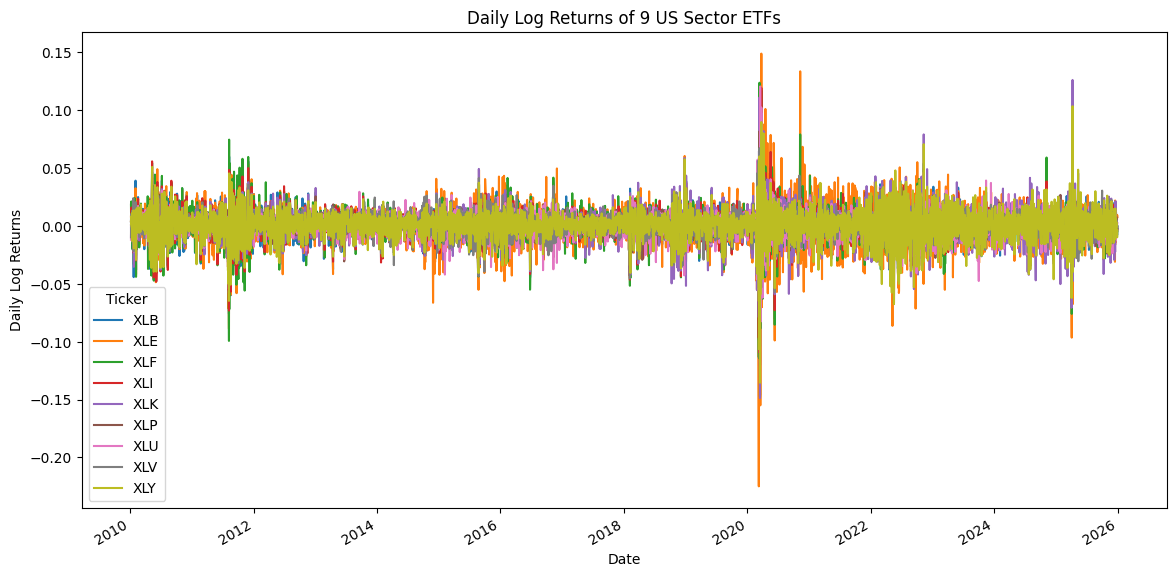

In [44]:
import matplotlib.pyplot as plt

sector_returns.plot(
    figsize=(14,7),
    title = "Daily Log Returns of 9 US Sector ETFs"
)

plt.xlabel("Date")
plt.ylabel("Daily Log Returns")
plt.show()

In [45]:
correlation_matrix = sector_returns.corr()
correlation_matrix

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,1.000000,0.722662,0.824177,0.883230,0.718068,0.652111,0.530820,0.709425,0.761855
XLE,0.722662,1.000000,0.704635,0.716431,0.521128,0.468113,0.409463,0.525891,0.555583
XLF,0.824177,0.704635,1.000000,0.876145,0.699029,0.646191,0.516940,0.709460,0.760179
XLI,0.883230,0.716431,0.876145,1.000000,0.767988,0.682554,0.563165,0.739751,0.811328
XLK,0.718068,0.521128,0.699029,0.767988,1.000000,0.585135,0.454033,0.686684,0.844782
XLP,0.652111,0.468113,0.646191,0.682554,0.585135,1.000000,0.697445,0.724735,0.624141
XLU,0.530820,0.409463,0.516940,0.563165,0.454033,0.697445,1.000000,0.567175,0.470817
XLV,0.709425,0.525891,0.709460,0.739751,0.686684,0.724735,0.567175,1.000000,0.682966
XLY,0.761855,0.555583,0.760179,0.811328,0.844782,0.624141,0.470817,0.682966,1.000000


In [46]:
np.allclose(correlation_matrix.values, correlation_matrix.values.T)

True

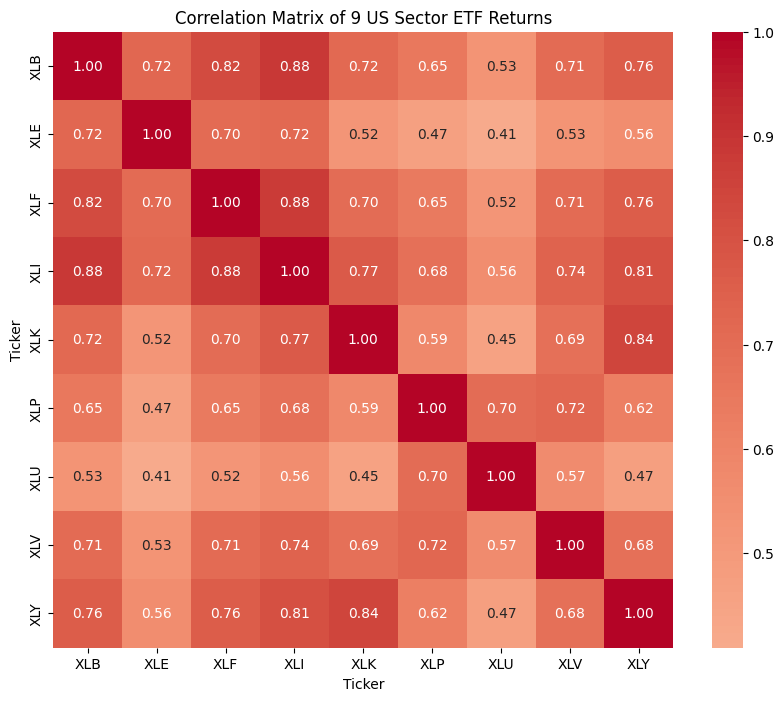

In [47]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center = 0
)

plt.title("Correlation Matrix of 9 US Sector ETF Returns")
plt.show()


In [48]:
rolling_vol_60 = (
    sector_returns.rolling(window=60).std() * np.sqrt(252)
)



In [49]:
rolling_vol_60.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [50]:
rolling_vol_60.dropna().head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-03-31,0.234928,0.200846,0.210133,0.166290,0.166572,0.094664,0.137360,0.142245,0.141337
2010-04-01,0.237496,0.203458,0.207690,0.166527,0.166589,0.095346,0.138390,0.141039,0.141713
2010-04-05,0.236271,0.205231,0.208443,0.166914,0.166636,0.095302,0.138414,0.139772,0.143313
2010-04-06,0.235707,0.205209,0.205240,0.165880,0.166406,0.095665,0.139176,0.139635,0.142674
2010-04-07,0.234377,0.205742,0.204961,0.163868,0.166129,0.096453,0.140636,0.139933,0.143024


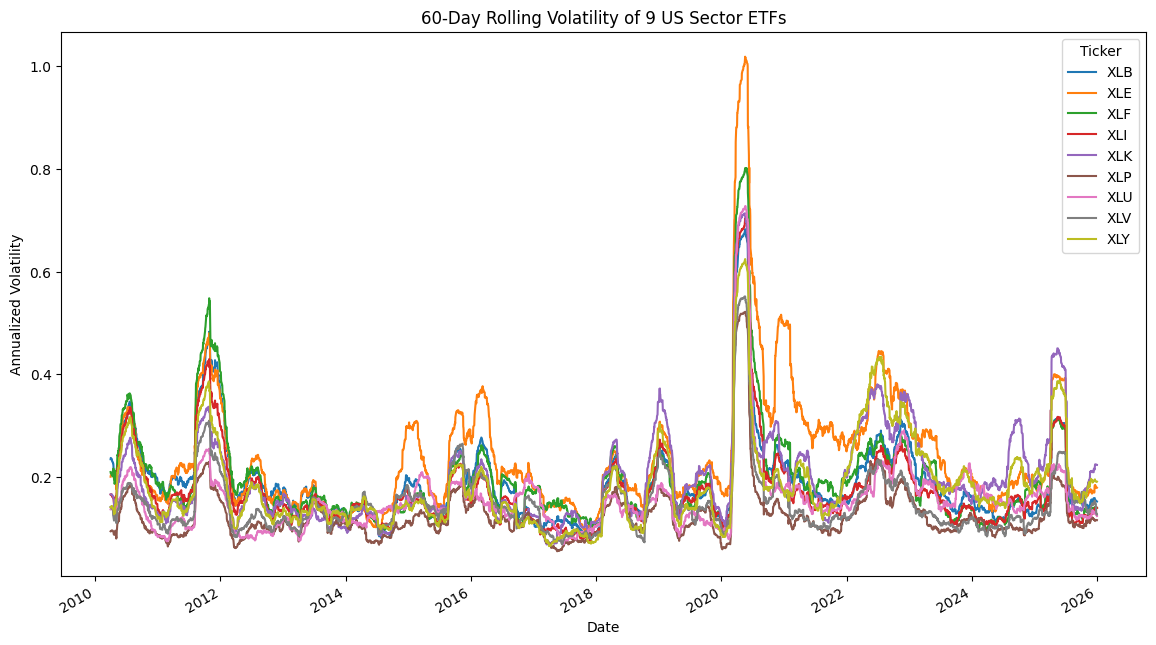

In [51]:
rolling_vol_60.plot(
    figsize=(14,8),
    title="60-Day Rolling Volatility of 9 US Sector ETFs"
)

plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.show()

In [52]:
rolling_corr_XLK_XLF = (
    sector_returns["XLK"].rolling(window=60).corr(sector_returns["XLF"])
)

In [53]:
rolling_corr_XLK_XLF.dropna().head()

,0
Date,
2010-03-31,0.722814
2010-04-01,0.732391
2010-04-05,0.742691
2010-04-06,0.766503
2010-04-07,0.776927


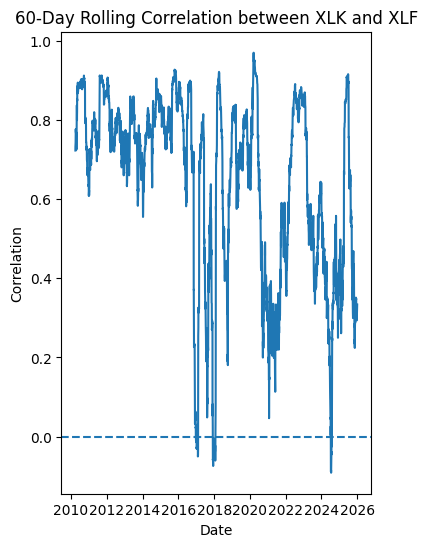

In [54]:
plt.figure(figsize=(4, 6))

plt.plot(
    rolling_corr_XLK_XLF.index,
    rolling_corr_XLK_XLF
)

plt.axhline(0, linestyle="--")

plt.title("60-Day Rolling Correlation between XLK and XLF")
plt.xlabel("Date")
plt.ylabel("Correlation")
plt.show()


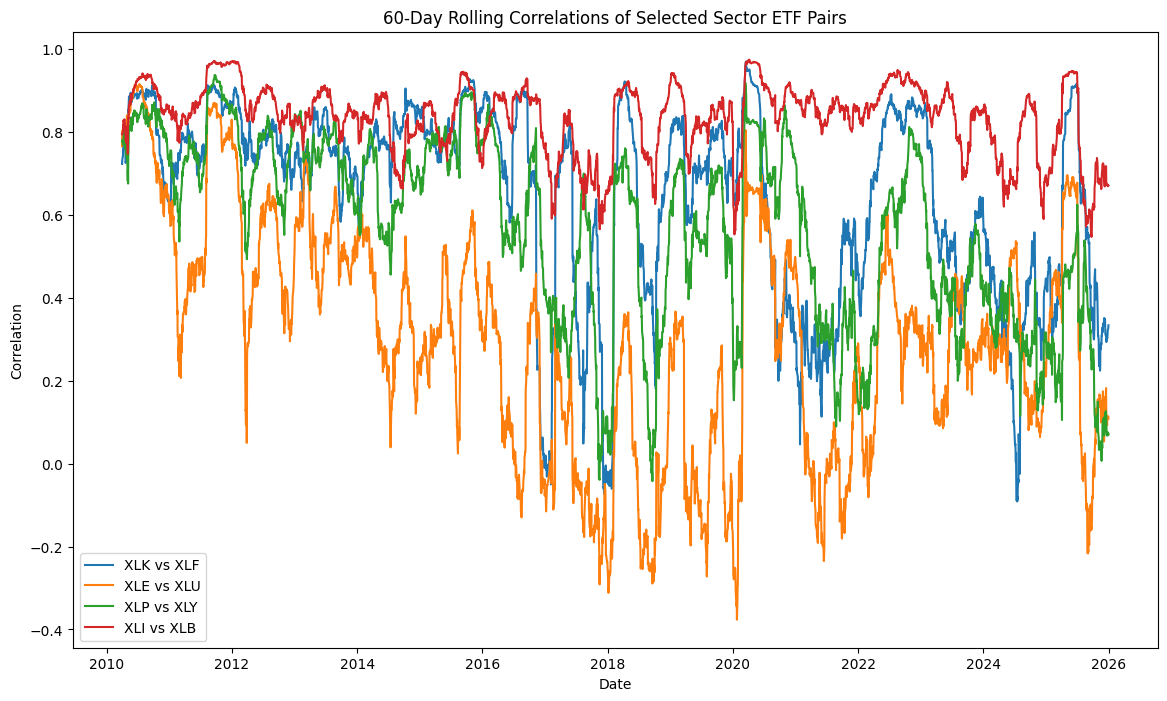

In [55]:
pairs = [
    ("XLK", "XLF"),
    ("XLE", "XLU"),
    ("XLP", "XLY"),
    ("XLI", "XLB")
     
]

plt.figure(figsize=(14, 8))

for etf1, etf2 in pairs:
    rolling_corr = (
        sector_returns[etf1].rolling(window=60).corr(sector_returns[etf2])
    )
    
    plt.plot(
        rolling_corr.index,
        rolling_corr,
        label=f"{etf1} vs {etf2}"
    )

plt.title("60-Day Rolling Correlations of Selected Sector ETF Pairs")
plt.xlabel("Date")
plt.ylabel("Correlation")
plt.legend()
plt.show()

In [56]:
spy_returns = returns["SPY"].copy()

In [57]:
spy_vol_60 = (
    spy_returns.rolling(window=60).std() * np.sqrt(252)
)

In [58]:
spy_vol_60.dropna().head()

,SPY
Date,
2010-03-31,0.141312
2010-04-01,0.141827
2010-04-05,0.142646
2010-04-06,0.142506
2010-04-07,0.143018


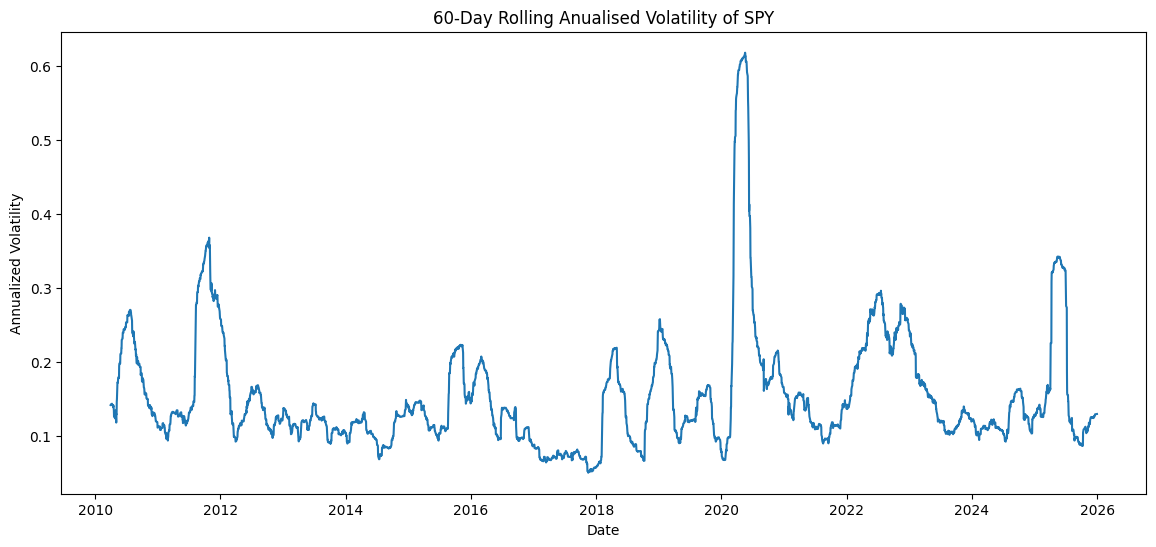

In [59]:
plt.figure(figsize=(14, 6))

plt.plot(
    spy_vol_60.index,
    spy_vol_60,
)

plt.title("60-Day Rolling Anualised Volatility of SPY")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.show()

In [60]:
sector_returns.to_csv(
    "sector_etf_daily_log_returns.csv"
)

In [61]:
summary_stats.to_csv(
    "sector_etf_summary_statistics.csv"
)

In [62]:
correlation_matrix.to_csv(
    "sector_etf_correlation_matrix.csv"
)

In [63]:
window = 60

historical_cov = (
    sector_returns.rolling(window=window).cov()
)

In [64]:
historical_cov.shape

(36198, 9)

In [65]:
historical_cov.tail(18)

Ticker                  XLB       XLE       XLF           XLI       XLK  \
Date       Ticker                                                         
2025-12-29 XLB     0.000092  0.000045  0.000064  5.691526e-05  0.000049   
           XLE     0.000045  0.000127  0.000034  3.033949e-05  0.000031   
           XLF     0.000064  0.000034  0.000079  5.219157e-05  0.000041   
           XLI     0.000057  0.000030  0.000052  7.774784e-05  0.000080   
           XLK     0.000049  0.000031  0.000041  7.957306e-05  0.000199   
           XLP     0.000029  0.000016  0.000028  4.393868e-07 -0.000038   
           XLU     0.000022  0.000010  0.000025  2.486912e-05  0.000024   
           XLV     0.000049  0.000021  0.000042  3.343328e-05  0.000006   
           XLY     0.000069  0.000032  0.000056  7.160899e-05  0.000108   
2025-12-30 XLB     0.000092  0.000045  0.000064  5.692562e-05  0.000049   
           XLE     0.000045  0.000128  0.000034  2.985799e-05  0.000031   
           XLF     0.000064  0.000034  0.000078  5.224669e-05  0.000042   
           XLI     0.000057  0.000030  0.000052  7.790049e-05  0.000080   
           XLK     0.000049  0.000031  0.000042  7.985939e-05  0.000199   
           XLP     0.000029  0.000016  0.000028  5.214622e-07 -0.000038   
           XLU     0.000022  0.000010  0.000024  2.451108e-05  0.000025   
           XLV     0.000049  0.000020  0.000041  3.337508e-05  0.000007   
           XLY     0.000069  0.000032  0.000057  7.195842e-05  0.000107   

Ticker                      XLP       XLU       XLV       XLY  
Date       Ticker                                              
2025-12-29 XLB     2.896752e-05  0.000022  0.000049  0.000069  
           XLE     1.627694e-05  0.000010  0.000021  0.000032  
           XLF     2.805063e-05  0.000025  0.000042  0.000056  
           XLI     4.393868e-07  0.000025  0.000033  0.000072  
           XLK    -3.849441e-05  0.000024  0.000006  0.000108  
           XLP     5.375276e-05  0.000012  0.000026  0.000006  
           XLU     1.231832e-05  0.000064  0.000018  0.000025  
           XLV     2.649463e-05  0.000018  0.000066  0.000034  
           XLY     6.090709e-06  0.000025  0.000034  0.000146  
2025-12-30 XLB     2.896573e-05  0.000022  0.000049  0.000069  
           XLE     1.596719e-05  0.000010  0.000020  0.000032  
           XLF     2.804387e-05  0.000024  0.000041  0.000057  
           XLI     5.214622e-07  0.000025  0.000033  0.000072  
           XLK    -3.829527e-05  0.000025  0.000007  0.000107  
           XLP     5.379441e-05  0.000012  0.000026  0.000006  
           XLU     1.203783e-05  0.000061  0.000016  0.000026  
           XLV     2.640004e-05  0.000016  0.000064  0.000036  
           XLY     6.334128e-06  0.000026  0.000036  0.000145

In [66]:
last_date = sector_returns.index[-1]

cov_last = historical_cov.loc[last_date]

cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000092,0.000045,0.000064,5.692562e-05,0.000049,2.896573e-05,0.000022,0.000049,0.000069
XLE,0.000045,0.000128,0.000034,2.985799e-05,0.000031,1.596719e-05,0.000010,0.000020,0.000032
XLF,0.000064,0.000034,0.000078,5.224669e-05,0.000042,2.804387e-05,0.000024,0.000041,0.000057
XLI,0.000057,0.000030,0.000052,7.790049e-05,0.000080,5.214622e-07,0.000025,0.000033,0.000072
XLK,0.000049,0.000031,0.000042,7.985939e-05,0.000199,-3.829527e-05,0.000025,0.000007,0.000107
XLP,0.000029,0.000016,0.000028,5.214622e-07,-0.000038,5.379441e-05,0.000012,0.000026,0.000006
XLU,0.000022,0.000010,0.000024,2.451108e-05,0.000025,1.203783e-05,0.000061,0.000016,0.000026
XLV,0.000049,0.000020,0.000041,3.337508e-05,0.000007,2.640004e-05,0.000016,0.000064,0.000036
XLY,0.000069,0.000032,0.000057,7.195842e-05,0.000107,6.334128e-06,0.000026,0.000036,0.000145


In [67]:
cov_last.shape

(9, 9)

In [68]:
cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000092,0.000045,0.000064,5.692562e-05,0.000049,2.896573e-05,0.000022,0.000049,0.000069
XLE,0.000045,0.000128,0.000034,2.985799e-05,0.000031,1.596719e-05,0.000010,0.000020,0.000032
XLF,0.000064,0.000034,0.000078,5.224669e-05,0.000042,2.804387e-05,0.000024,0.000041,0.000057
XLI,0.000057,0.000030,0.000052,7.790049e-05,0.000080,5.214622e-07,0.000025,0.000033,0.000072
XLK,0.000049,0.000031,0.000042,7.985939e-05,0.000199,-3.829527e-05,0.000025,0.000007,0.000107
XLP,0.000029,0.000016,0.000028,5.214622e-07,-0.000038,5.379441e-05,0.000012,0.000026,0.000006
XLU,0.000022,0.000010,0.000024,2.451108e-05,0.000025,1.203783e-05,0.000061,0.000016,0.000026
XLV,0.000049,0.000020,0.000041,3.337508e-05,0.000007,2.640004e-05,0.000016,0.000064,0.000036
XLY,0.000069,0.000032,0.000057,7.195842e-05,0.000107,6.334128e-06,0.000026,0.000036,0.000145


In [69]:
np.allclose(cov_last.values, cov_last.values.T)

True

## EWMA covariance

Historical covariance gives every observation within the window effectively equal importance.

EWMA instead gives more recent observations greater weight.

So recent market behaviour influences the estimate more strongly.

In [70]:
lambda_ = 0.94

In [71]:
def ewma_covariance(returns_window, lambda_ =0.94):

    X = returns_window.values

    weights = np.array([
        (1 - lambda_) * lambda_ ** i
        for i in range(len(X))
    ])[::-1]  # Reverse the weights to align with the most recent observation

    weights = weights / weights.sum()  # Normalize the weights to sum to 1

    mean = np.average(
        X,
        axis=0,
        weights=weights
    ) 

    X_centered = X - mean

    cov = (
        X_centered.T @ (X_centered * weights[:, None])
    ) 

    return pd.DataFrame(
        cov,
        index=returns_window.columns,
        columns=returns_window.columns
    )   
                    

In [72]:
import pandas as pd
import numpy as np

latest_window = sector_returns.iloc[-60:]  # Get the last 60 rows of sector_returns

In [73]:
ewma_cov_last = ewma_covariance(
    latest_window,
    lambda_=0.94
)

ewma_cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000070,0.000027,0.000049,3.962749e-05,2.029785e-05,2.149722e-05,0.000016,4.344813e-05,0.000045
XLE,0.000027,0.000130,0.000020,4.340716e-06,-8.418535e-06,1.403618e-05,0.000002,1.415880e-05,-0.000009
XLF,0.000049,0.000020,0.000052,4.150819e-05,2.290798e-05,1.546198e-05,0.000014,3.558451e-05,0.000037
XLI,0.000040,0.000004,0.000042,6.406689e-05,6.025809e-05,-7.917021e-07,0.000019,3.500148e-05,0.000049
XLK,0.000020,-0.000008,0.000023,6.025809e-05,1.486989e-04,-3.306217e-05,0.000009,8.874994e-07,0.000053
XLP,0.000021,0.000014,0.000015,-7.917021e-07,-3.306217e-05,3.523132e-05,0.000008,2.026722e-05,0.000008
XLU,0.000016,0.000002,0.000014,1.931365e-05,8.949587e-06,8.451317e-06,0.000053,1.809404e-05,0.000025
XLV,0.000043,0.000014,0.000036,3.500148e-05,8.874994e-07,2.026722e-05,0.000018,6.104612e-05,0.000033
XLY,0.000045,-0.000009,0.000037,4.850338e-05,5.269549e-05,8.290636e-06,0.000025,3.280933e-05,0.000092


In [74]:
ewma_cov_last.shape

(9, 9)

In [75]:
np.allclose(
    ewma_cov_last.values,
    ewma_cov_last.values.T
)

True

In [76]:
cov_difference = ewma_cov_last - cov_last

cov_difference

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,-0.000022,-0.000018,-0.000015,-0.000017,-0.000029,-0.000007,-5.887890e-06,-0.000006,-2.445640e-05
XLE,-0.000018,0.000002,-0.000014,-0.000026,-0.000039,-0.000002,-7.326060e-06,-0.000006,-4.035839e-05
XLF,-0.000015,-0.000014,-0.000027,-0.000011,-0.000019,-0.000013,-9.968337e-06,-0.000006,-2.029763e-05
XLI,-0.000017,-0.000026,-0.000011,-0.000014,-0.000020,-0.000001,-5.197434e-06,0.000002,-2.345503e-05
XLK,-0.000029,-0.000039,-0.000019,-0.000020,-0.000050,0.000005,-1.583040e-05,-0.000006,-5.455633e-05
XLP,-0.000007,-0.000002,-0.000013,-0.000001,0.000005,-0.000019,-3.586514e-06,-0.000006,1.956509e-06
XLU,-0.000006,-0.000007,-0.000010,-0.000005,-0.000016,-0.000004,-8.096143e-06,0.000002,-8.350607e-07
XLV,-0.000006,-0.000006,-0.000006,0.000002,-0.000006,-0.000006,2.251837e-06,-0.000003,-2.960947e-06
XLY,-0.000024,-0.000040,-0.000020,-0.000023,-0.000055,0.000002,-8.350607e-07,-0.000003,-5.374699e-05


In [77]:
np.allclose(
    ewma_cov_last.values,
    cov_last.values
)

False

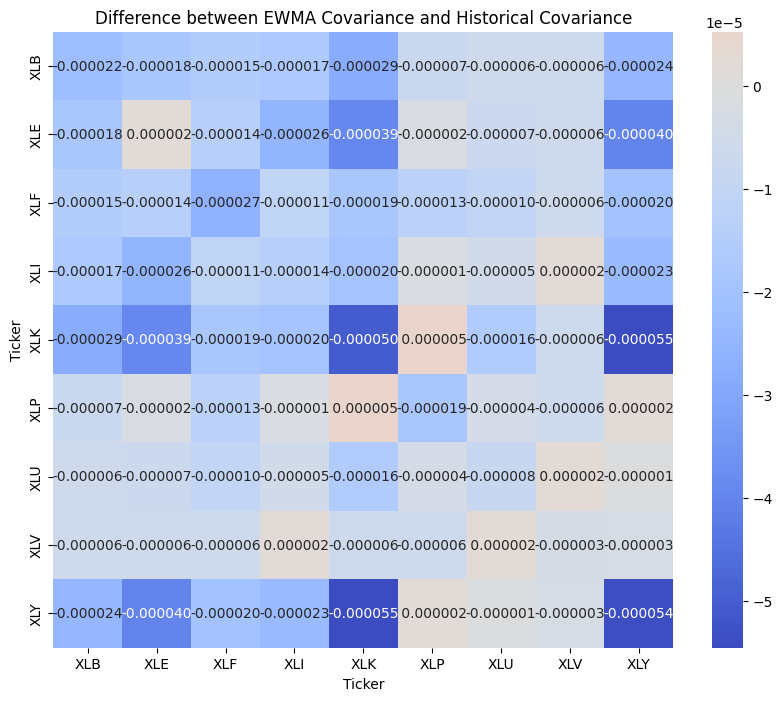

In [78]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

sns.heatmap(
    cov_difference,
    annot=True,
    fmt=" .6f",
    cbar=True,
    center=0,
    cmap="coolwarm"
)

plt.title("Difference between EWMA Covariance and Historical Covariance")

plt.show()

### EWMA vs Historical Covariance

The heatmap shows the difference between the EWMA and historical
covariance estimates for the latest observation window.

Positive values indicate that EWMA produces a higher covariance
estimate, while negative values indicate a lower estimate.

The differences confirm that EWMA responds differently from the
equally weighted historical estimator because it places greater
weight on recent observations. The largest diagonal difference is
observed for XLK, indicating a notable difference in the estimated
recent variance of the technology sector.

The difference matrix is symmetric, as expected for covariance
matrices.

In [79]:
historical_eigenvalues = np.linalg.eigvals(cov_last.values)

historical_eigenvalues

array([4.37241471e-04, 1.77051635e-04, 1.02832334e-04, 5.39284655e-05,
       4.50152884e-05, 1.30172715e-05, 1.93819199e-05, 2.88622168e-05,
       2.32919812e-05])

In [80]:
ewma_eigenvalues = np.linalg.eigvals(ewma_cov_last.values)

ewma_eigenvalues

array([2.85170556e-04, 1.70250320e-04, 1.11009389e-04, 4.62338443e-05,
       3.50578319e-05, 7.02429900e-06, 2.22055857e-05, 1.31870839e-05,
       1.58133129e-05])

In [81]:
print(
    "Historical minimum eigenvalues:",
    historical_eigenvalues.min()
    
)

print(
    "EWMA minimum eigenvalues:",
    ewma_eigenvalues.min()
)

Historical minimum eigenvalues: 1.301727152972944e-05
EWMA minimum eigenvalues: 7.02429899557015e-06


In [82]:
tolerance = 1e-10

print(
    "Historical PSD:",
    historical_eigenvalues.min() >= -tolerance
)

print(
    "EWMA PSD:",
    ewma_eigenvalues.min() >= -tolerance
)

Historical PSD: True
EWMA PSD: True


In [83]:
sector_returns.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-01-05,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009855,0.003660
2010-01-06,0.016851,0.011904,0.002003,0.002109,-0.011250,-0.000750,0.005844,0.010171,0.001328
2010-01-07,-0.007809,-0.001501,0.021123,0.010826,-0.003925,0.000000,-0.004542,0.003473,0.008258
2010-01-08,0.013841,0.006489,-0.005896,0.015852,0.006532,-0.003381,-0.000977,0.001575,-0.000329
2010-01-11,-0.005456,-0.001328,0.000657,0.010881,-0.003914,0.002631,0.010363,0.005648,-0.001976


In [84]:
sector_returns.shape

(4022, 9)

In [85]:
sector_returns.columns

Index(['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY'], dtype='object', name='Ticker')

In [86]:
window = 60

In [87]:
historical_cov = (
    sector_returns
    .rolling(window=window)
    .cov()
)

In [88]:
historical_cov.head()

Ticker             XLB  XLE  XLF  XLI  XLK  XLP  XLU  XLV  XLY
Date       Ticker                                             
2010-01-05 XLB     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLE     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLF     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLI     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLK     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN

In [89]:
historical_cov.shape

(36198, 9)

In [90]:
last_date = sector_returns.index[-1]

print(last_date)

2025-12-30 00:00:00


In [91]:
cov_last = historical_cov.loc[last_date]

cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000092,0.000045,0.000064,5.692562e-05,0.000049,2.896573e-05,0.000022,0.000049,0.000069
XLE,0.000045,0.000128,0.000034,2.985799e-05,0.000031,1.596719e-05,0.000010,0.000020,0.000032
XLF,0.000064,0.000034,0.000078,5.224669e-05,0.000042,2.804387e-05,0.000024,0.000041,0.000057
XLI,0.000057,0.000030,0.000052,7.790049e-05,0.000080,5.214622e-07,0.000025,0.000033,0.000072
XLK,0.000049,0.000031,0.000042,7.985939e-05,0.000199,-3.829527e-05,0.000025,0.000007,0.000107
XLP,0.000029,0.000016,0.000028,5.214622e-07,-0.000038,5.379441e-05,0.000012,0.000026,0.000006
XLU,0.000022,0.000010,0.000024,2.451108e-05,0.000025,1.203783e-05,0.000061,0.000016,0.000026
XLV,0.000049,0.000020,0.000041,3.337508e-05,0.000007,2.640004e-05,0.000016,0.000064,0.000036
XLY,0.000069,0.000032,0.000057,7.195842e-05,0.000107,6.334128e-06,0.000026,0.000036,0.000145


In [92]:
cov_last.shape

(9, 9)

In [93]:
cov_last.loc["XLK", "XLK"]

np.float64(0.00019892778593655355)

In [94]:
np.allclose(
    cov_last.values,
    cov_last.values.T
)

True

In [95]:
print(cov_last.loc["XLK", "XLF"])
print(cov_last.loc["XLF", "XLK"])

4.167279151696884e-05
4.167279151696884e-05


In [96]:
pd.Series(
    np.diag(cov_last),
    index = cov_last.columns,
    name = "Variance"
)

,Variance
Ticker,
XLB,0.000092
XLE,0.000128
XLF,0.000078
XLI,0.000078
XLK,0.000199
XLP,0.000054
XLU,0.000061
XLV,0.000064
XLY,0.000145


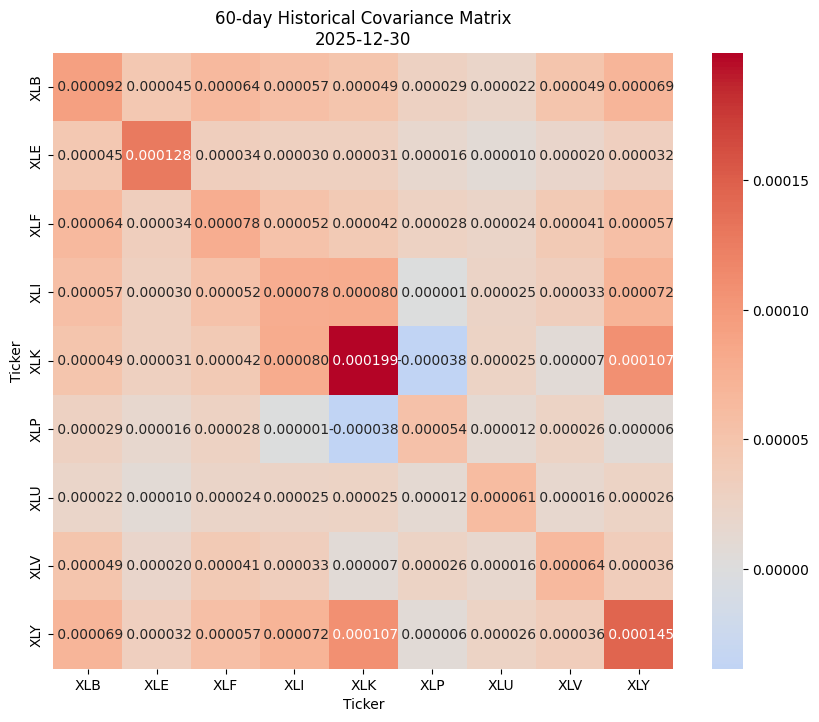

In [97]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (10, 8))

sns.heatmap(
    cov_last,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title(
    f"60-day Historical Covariance Matrix\n{last_date.date()}"
)

plt.show()

In [98]:
first_valid_date = (
    historical_cov
    .dropna()
    .index
    .get_level_values(0)[0]
)

print("First valid covariance date:", first_valid_date)

First valid covariance date: 2010-03-31 00:00:00


In [99]:
latest_60_returns = sector_returns.iloc[-60:]

In [100]:
manual_cov = latest_60_returns.cov()

In [101]:
np.allclose(
    manual_cov.values,
    cov_last.values
)

True

### Historical Covariance Baseline

A rolling sample covariance estimator was implemented using a
60-trading-day lookback window. At each date, the covariance matrix
is estimated using only the observations contained within the
historical window.

The estimator produces a 9 × 9 covariance matrix corresponding to
the nine US sector ETFs.

The 60-day window is initially used for baseline implementation and
will be treated as an experimental design choice rather than assumed
to be universally optimal.

The historical covariance estimator provides a transparent empirical
baseline against which more adaptive and regularised covariance
estimators can be evaluated.

In [102]:
lambda_ = 0.94

In [103]:
latest_window = sector_returns.iloc[-window:]

latest_window.shape

(60, 9)

In [104]:
latest_window.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2025-10-06,-0.000890,0.004937,-0.000372,0.004652,0.010064,-0.007332,0.009626,-0.004845,0.008540
2025-10-07,-0.004018,0.001566,0.001303,-0.005689,-0.006698,0.009252,0.004557,0.000763,-0.017662
2025-10-08,0.005354,-0.005828,-0.004847,0.008650,0.017385,-0.005001,0.006852,0.001940,0.002966
2025-10-09,-0.013776,-0.013694,-0.003557,-0.014893,-0.001687,0.003209,-0.002536,-0.002217,-0.005004
2025-10-10,-0.020739,-0.029370,-0.021996,-0.022363,-0.041547,0.000768,-0.004094,-0.014530,-0.027892


In [105]:
latest_window.tail()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2025-12-23,0.001750,0.006538,0.001986,-0.000382,0.005428,-0.004762,0.003526,-0.001998,-0.001390
2025-12-24,0.001965,-0.002925,0.005398,0.003243,0.002395,0.007839,0.004448,0.005213,0.003432
2025-12-26,0.005873,-0.003839,-0.001976,-0.001843,0.001571,0.001407,-0.000701,0.001603,-0.004415
2025-12-29,-0.008057,0.009457,-0.005408,-0.002165,-0.004514,0.000639,0.001868,-0.001539,-0.009881
2025-12-30,-0.000219,0.007591,-0.002534,-0.002873,-0.003158,-0.001662,0.002330,-0.000835,-0.004063


In [106]:
def ewma_covariance(returns_window, lambda_ =0.94):
    X = returns_window.values

    n = len(X)

    weights = np.array([
        (1 - lambda_) * lambda_ ** i
        for i in range(n)
    ])[::-1]

    weights = weights / weights.sum()

    mean = np.average(
        X,
        axis=0,
        weights=weights
    )

    X_centered = X - mean

    cov = (
        X_centered.T
        @ (X_centered * weights[:, None])
    )

    return pd.DataFrame(
        cov,
        index=returns_window.columns,
        columns=returns_window.columns
    )

In [107]:
lambda_ = 0.94
n = window

weights = np.array([
    (1 - lambda_) * lambda_ ** i
    for i in range(n)
])[::-1]

weights = weights / weights.sum()

In [108]:
weights[:5]

array([0.00159746, 0.00169943, 0.0018079 , 0.0019233 , 0.00204606])

In [109]:
weights[-5:]

array([0.04801732, 0.05108225, 0.05434282, 0.05781152, 0.06150161])

In [110]:
weights.sum()

np.float64(1.0)

<function matplotlib.pyplot.show(close=None, block=None)>

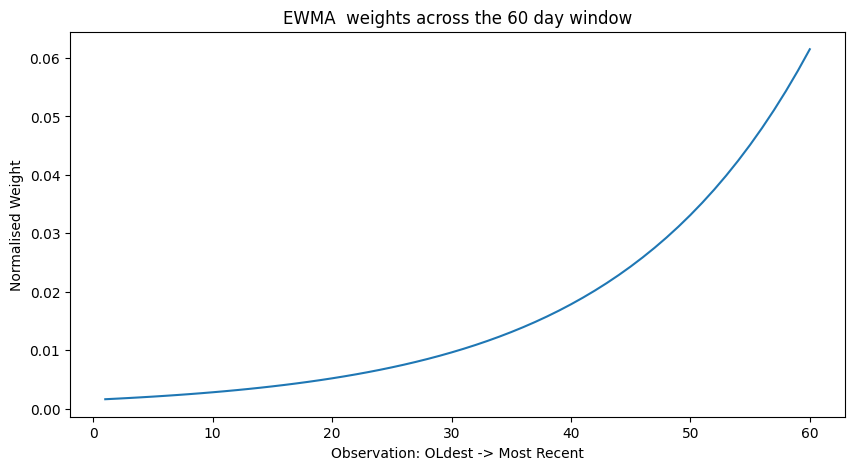

In [111]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, window + 1),
    weights
)

plt.title("EWMA  weights across the 60 day window")
plt.xlabel("Observation: OLdest -> Most Recent")
plt.ylabel("Normalised Weight")

plt.show

In [112]:
ewma_cov_last = ewma_covariance(
    latest_window,
    lambda_=0.94
)

ewma_cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000070,0.000027,0.000049,3.962749e-05,2.029785e-05,2.149722e-05,0.000016,4.344813e-05,0.000045
XLE,0.000027,0.000130,0.000020,4.340716e-06,-8.418535e-06,1.403618e-05,0.000002,1.415880e-05,-0.000009
XLF,0.000049,0.000020,0.000052,4.150819e-05,2.290798e-05,1.546198e-05,0.000014,3.558451e-05,0.000037
XLI,0.000040,0.000004,0.000042,6.406689e-05,6.025809e-05,-7.917021e-07,0.000019,3.500148e-05,0.000049
XLK,0.000020,-0.000008,0.000023,6.025809e-05,1.486989e-04,-3.306217e-05,0.000009,8.874994e-07,0.000053
XLP,0.000021,0.000014,0.000015,-7.917021e-07,-3.306217e-05,3.523132e-05,0.000008,2.026722e-05,0.000008
XLU,0.000016,0.000002,0.000014,1.931365e-05,8.949587e-06,8.451317e-06,0.000053,1.809404e-05,0.000025
XLV,0.000043,0.000014,0.000036,3.500148e-05,8.874994e-07,2.026722e-05,0.000018,6.104612e-05,0.000033
XLY,0.000045,-0.000009,0.000037,4.850338e-05,5.269549e-05,8.290636e-06,0.000025,3.280933e-05,0.000092


In [113]:
ewma_cov_last.shape

(9, 9)

In [114]:
np.allclose(
    ewma_cov_last.values,
    ewma_cov_last.values.T
)

True

In [115]:
print(ewma_cov_last.loc["XLK", "XLF"])
print(ewma_cov_last.loc["XLF", "XLK"])

2.2907978657414476e-05
2.2907978657414476e-05


In [116]:
pd.Series(
    np.diag(ewma_cov_last),
    index=ewma_cov_last.columns,
    name="EWMA Variance"
)

,EWMA Variance
Ticker,
XLB,0.000070
XLE,0.000130
XLF,0.000052
XLI,0.000064
XLK,0.000149
XLP,0.000035
XLU,0.000053
XLV,0.000061
XLY,0.000092


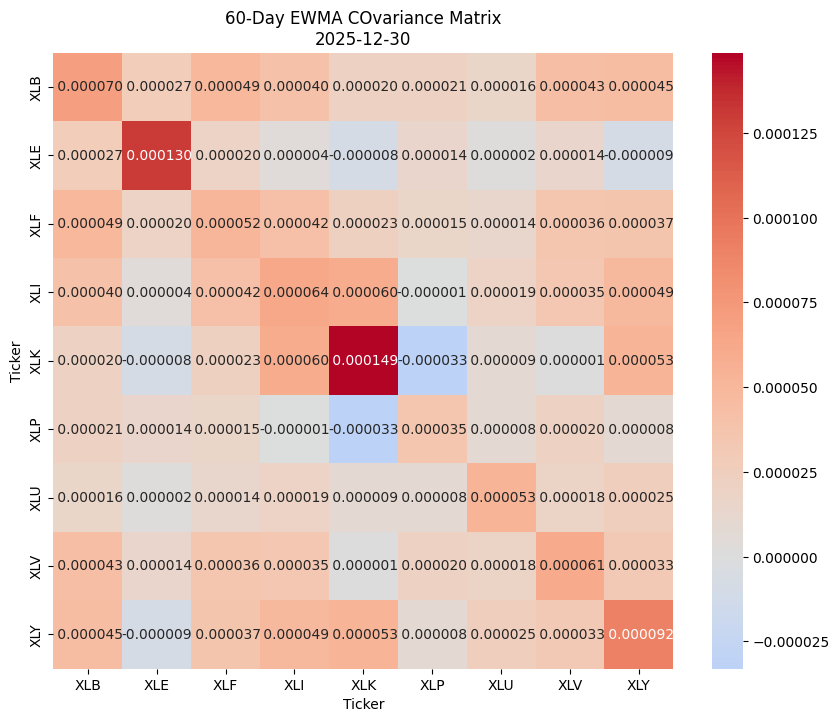

In [117]:
plt.figure(figsize=(10,8))

sns.heatmap(
    ewma_cov_last,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title(
    f"60-Day EWMA COvariance Matrix\n{last_date.date()}"
)

plt.show()

In [118]:
print(
    "Historical XLK-XLF:",
    cov_last.loc["XLK", "XLF"]
)

print(
    "EWMA XLK-XLF:",
    ewma_cov_last.loc["XLK", "XLF"]
)

Historical XLK-XLF: 4.167279151696884e-05
EWMA XLK-XLF: 2.2907978657414476e-05


### EWMA Covariance Baseline

An Exponentially Weighted Moving Average (EWMA) covariance estimator
was implemented as a time-responsive baseline.

The estimator uses the same 60-trading-day information window as the
historical covariance baseline but assigns greater weight to more
recent observations through exponential decay.

An initial decay factor of λ = 0.94 is used for baseline
implementation. This value is treated as an experimental parameter
rather than assumed to be universally optimal.

EWMA provides a useful comparator because it introduces predetermined
temporal adaptation without learning estimator-selection or
combination behaviour from market-state variables.

In [119]:

print("Historical shape:", cov_last.shape)
print("EWMA shape:", ewma_cov_last.shape)

print(
    "Same assets:",
    list(cov_last.columns) == list(ewma_cov_last.columns)
)

Historical shape: (9, 9)
EWMA shape: (9, 9)
Same assets: True


In [120]:
cov_difference = ewma_cov_last - cov_last

cov_difference

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,-0.000022,-0.000018,-0.000015,-0.000017,-0.000029,-0.000007,-5.887890e-06,-0.000006,-2.445640e-05
XLE,-0.000018,0.000002,-0.000014,-0.000026,-0.000039,-0.000002,-7.326060e-06,-0.000006,-4.035839e-05
XLF,-0.000015,-0.000014,-0.000027,-0.000011,-0.000019,-0.000013,-9.968337e-06,-0.000006,-2.029763e-05
XLI,-0.000017,-0.000026,-0.000011,-0.000014,-0.000020,-0.000001,-5.197434e-06,0.000002,-2.345503e-05
XLK,-0.000029,-0.000039,-0.000019,-0.000020,-0.000050,0.000005,-1.583040e-05,-0.000006,-5.455633e-05
XLP,-0.000007,-0.000002,-0.000013,-0.000001,0.000005,-0.000019,-3.586514e-06,-0.000006,1.956509e-06
XLU,-0.000006,-0.000007,-0.000010,-0.000005,-0.000016,-0.000004,-8.096143e-06,0.000002,-8.350607e-07
XLV,-0.000006,-0.000006,-0.000006,0.000002,-0.000006,-0.000006,2.251837e-06,-0.000003,-2.960947e-06
XLY,-0.000024,-0.000040,-0.000020,-0.000023,-0.000055,0.000002,-8.350607e-07,-0.000003,-5.374699e-05


In [121]:
cov_difference.loc["XLK", "XLF"]

np.float64(-1.8764812859554364e-05)

In [122]:
np.allclose(
    ewma_cov_last.values,
    cov_last.values
)

False

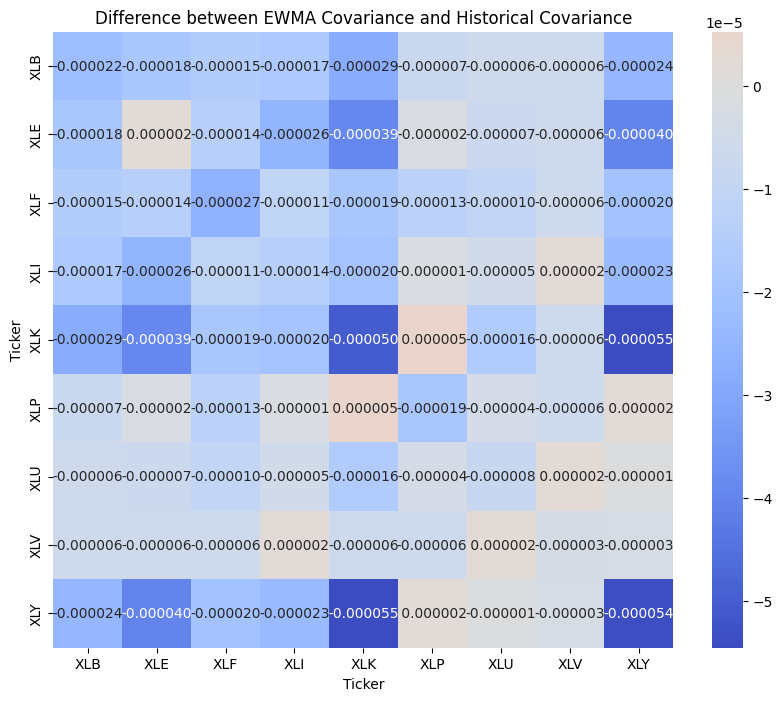

In [123]:
plt.figure(figsize=(10,8))

sns.heatmap(
    cov_difference,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title("Difference between EWMA Covariance and Historical Covariance")

plt.show()

In [124]:
variance_comparison = pd.DataFrame({
    "Historical": np.diag(cov_last),
    "EWMA": np.diag(ewma_cov_last)
}, index=cov_last.columns)

variance_comparison["Difference"] = (
    variance_comparison["EWMA"] - variance_comparison["Historical"]
)

variance_comparison

,Historical,EWMA,Difference
Ticker,,,
XLB,0.000092,0.000070,-0.000022
XLE,0.000128,0.000130,0.000002
XLF,0.000078,0.000052,-0.000027
XLI,0.000078,0.000064,-0.000014
XLK,0.000199,0.000149,-0.000050
XLP,0.000054,0.000035,-0.000019
XLU,0.000061,0.000053,-0.000008
XLV,0.000064,0.000061,-0.000003
XLY,0.000145,0.000092,-0.000054


In [125]:
frobenius_difference = np.linalg.norm(
    ewma_cov_last.values - cov_last.values,
    ord="fro"
)

print(
    "Frobenius distance between Historical and EWMA:",
    frobenius_difference)

Frobenius distance between Historical and EWMA: 0.00017657918745962845


### Historical vs EWMA Covariance

The Historical and EWMA estimators produce different covariance
estimates despite being calculated from the same 60-day information
window.

The Historical estimator treats observations approximately equally,
whereas EWMA assigns greater importance to recent observations.
Consequently, differences are observed in both individual asset
variances and cross-asset covariances.

These differences do not establish that either estimator is superior.
Their relative usefulness must be evaluated out of sample, particularly
through their downstream effect on portfolio risk and stability.

In [126]:
historical_eigenvalues = np.linalg.eigvalsh(
    cov_last.values
)

historical_eigenvalues

array([1.30172715e-05, 1.93819199e-05, 2.32919812e-05, 2.88622168e-05,
       4.50152884e-05, 5.39284655e-05, 1.02832334e-04, 1.77051635e-04,
       4.37241471e-04])

In [127]:
print(
    "Historical minimum eigenvalue:",
    historical_eigenvalues.min()
)

Historical minimum eigenvalue: 1.3017271529729427e-05


In [128]:
ewma_eigenvalues = np.linalg.eigvalsh(
    ewma_cov_last.values
)

ewma_eigenvalues

array([7.02429900e-06, 1.31870839e-05, 1.58133129e-05, 2.22055857e-05,
       3.50578319e-05, 4.62338443e-05, 1.11009389e-04, 1.70250320e-04,
       2.85170556e-04])

In [129]:
print(
    "EWMA minimum eigenvalue:",
    ewma_eigenvalues.min()
)

EWMA minimum eigenvalue: 7.0242989955701375e-06


In [130]:
tolerance = 1e-10

historical_psd = (
    historical_eigenvalues.min() >= -tolerance
)

ewma_psd = (
    ewma_eigenvalues.min() >= -tolerance
)

print("Historical PSD:", historical_psd)
print("EWMA PSD:", ewma_psd)

Historical PSD: True
EWMA PSD: True


In [131]:
eigenvalue_comparison = pd.DataFrame({
    "HIstorical": historical_eigenvalues,
    "EWMA": ewma_eigenvalues
})

eigenvalue_comparison.index = [
    f"Eigenvalue {i+1}"
    for i in range(len(eigenvalue_comparison))
]

eigenvalue_comparison

,HIstorical,EWMA
Eigenvalue 1,0.000013,0.000007
Eigenvalue 2,0.000019,0.000013
Eigenvalue 3,0.000023,0.000016
Eigenvalue 4,0.000029,0.000022
Eigenvalue 5,0.000045,0.000035
Eigenvalue 6,0.000054,0.000046
Eigenvalue 7,0.000103,0.000111
Eigenvalue 8,0.000177,0.000170
Eigenvalue 9,0.000437,0.000285


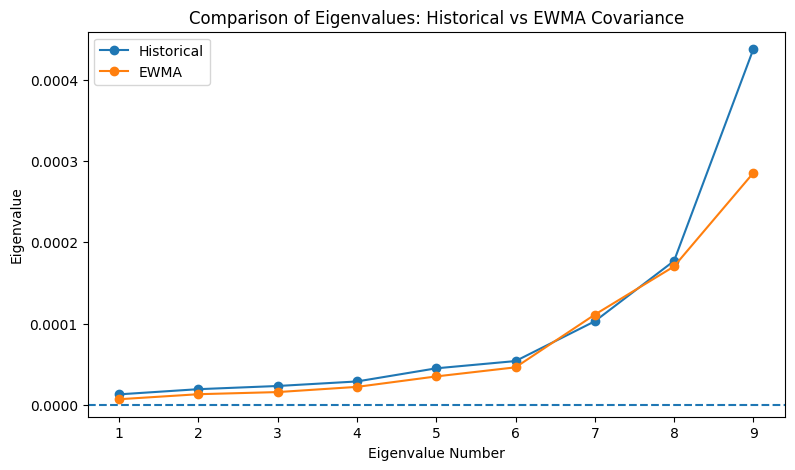

In [132]:
plt.figure(figsize=(9,5))

plt.plot(
    range(1, 10),
    historical_eigenvalues,
    marker="o",
    label="Historical"
)

plt.plot(
    range(1, 10),
    ewma_eigenvalues,
    marker="o",
    label="EWMA"
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Eigenvalue Number")
plt.ylabel("Eigenvalue")
plt.title("Comparison of Eigenvalues: Historical vs EWMA Covariance")
plt.legend()

plt.show()

In [133]:
print(
    "HIstorical postivie definite:",
    historical_eigenvalues.min() >= tolerance
)

print(
    "EWMA postivie definite:",
    ewma_eigenvalues.min() >= tolerance
)

HIstorical postivie definite: True
EWMA postivie definite: True


In [134]:
historical_condition = np.linalg.cond(
    cov_last.values
)

wema_condition = np.linalg.cond(
    ewma_cov_last.values
)

print(
    "Historical condition number:",
    historical_condition
)

print(
    "EWMA condition number:",
    wema_condition
)


Historical condition number: 33.589333189845114
EWMA condition number: 40.59772454111911


### Covariance Validity and Eigenvalue Diagnostics

The Historical and EWMA covariance estimates were assessed for
positive semi-definiteness (PSD), an important mathematical property
of covariance matrices.

For a symmetric covariance matrix, PSD can be evaluated by examining
its eigenvalues. A matrix is PSD when its eigenvalues are
non-negative, subject to a small numerical tolerance for floating-point
error.

The minimum eigenvalue of each covariance estimate was therefore
examined alongside its overall eigenvalue spectrum. Condition numbers
were also calculated as an initial diagnostic of numerical
conditioning.

These checks establish mathematical and numerical diagnostics for the
baseline estimators before they are incorporated into downstream
portfolio optimisation.

In [135]:
from sklearn.covariance import LedoitWolf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [136]:
window = 60

latest_window = sector_returns.iloc[-window:].copy()

print("Window shape:", latest_window.shape)
print("Start date:", latest_window.index[0])
print("End date:", latest_window.index[-1])

Window shape: (60, 9)
Start date: 2025-10-06 00:00:00
End date: 2025-12-30 00:00:00


In [137]:
lw_model = LedoitWolf(
    assume_centered=False,
)

lw_model.fit(latest_window.values)

LedoitWolf()

In [138]:
shrinkage_cov_last = pd.DataFrame(
    lw_model.covariance_,
    index=latest_window.columns,
    columns=latest_window.columns
)

shrinkage_cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000092,0.000039,0.000055,4.888864e-05,0.000042,2.487623e-05,0.000019,0.000042,0.000059
XLE,0.000039,0.000122,0.000029,2.564252e-05,0.000026,1.371288e-05,0.000008,0.000017,0.000027
XLF,0.000055,0.000029,0.000080,4.487030e-05,0.000036,2.408453e-05,0.000020,0.000035,0.000049
XLI,0.000049,0.000026,0.000045,7.936253e-05,0.000069,4.478402e-07,0.000021,0.000029,0.000062
XLK,0.000042,0.000026,0.000036,6.858453e-05,0.000183,-3.288859e-05,0.000021,0.000006,0.000092
XLP,0.000025,0.000014,0.000024,4.478402e-07,-0.000033,5.865985e-05,0.000010,0.000023,0.000005
XLU,0.000019,0.000008,0.000020,2.105051e-05,0.000021,1.033828e-05,0.000065,0.000014,0.000022
XLV,0.000042,0.000017,0.000035,2.866306e-05,0.000006,2.267278e-05,0.000014,0.000068,0.000031
XLY,0.000059,0.000027,0.000049,6.179904e-05,0.000092,5.439851e-06,0.000022,0.000031,0.000137


In [139]:
shrinkage_cov_last.shape

(9, 9)

In [140]:
shrinkage_intensity = lw_model.shrinkage_

print("Shrinkage intensity:", shrinkage_intensity)

Shrinkage intensity: 0.12662772094377678


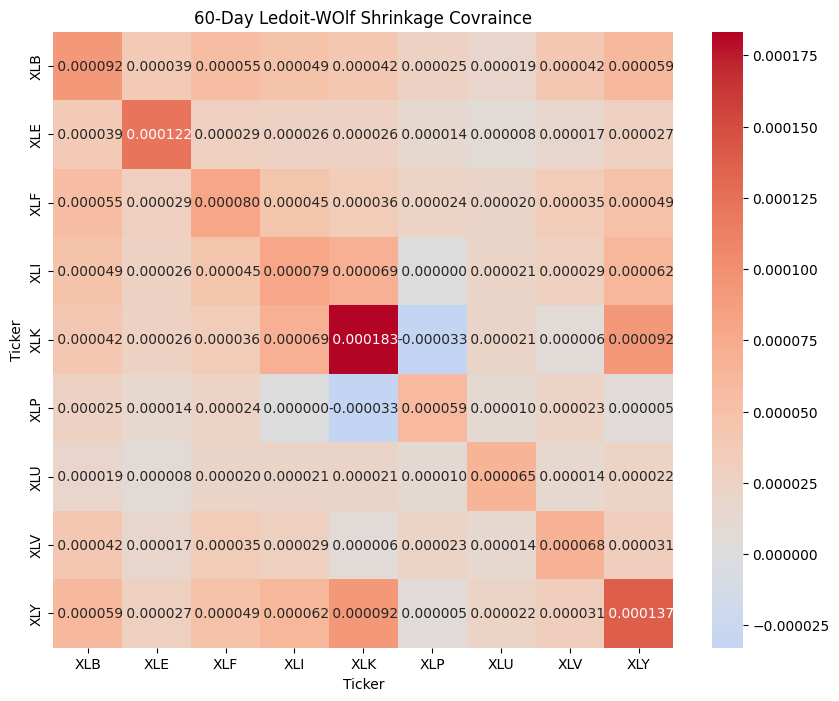

In [141]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    shrinkage_cov_last,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "60-Day Ledoit-WOlf Shrinkage Covraince"
)

plt.show()

In [142]:
variance_comparison_3 = pd.DataFrame({
    "Historical": np.diag(cov_last.values),
    "EWMA": np.diag(ewma_cov_last.values),
    "Ledoit-Wolf": np.diag(shrinkage_cov_last.values)
}, index=sector_returns.columns)

variance_comparison_3

,Historical,EWMA,Ledoit-Wolf
Ticker,,,
XLB,0.000092,0.000070,0.000092
XLE,0.000128,0.000130,0.000122
XLF,0.000078,0.000052,0.000080
XLI,0.000078,0.000064,0.000079
XLK,0.000199,0.000149,0.000183
XLP,0.000054,0.000035,0.000059
XLU,0.000061,0.000053,0.000065
XLV,0.000064,0.000061,0.000068
XLY,0.000145,0.000092,0.000137


In [143]:
print(
    "HIstorical vs EWMA:",
    np.linalg.norm(
        cov_last.values - ewma_cov_last.values,
        ord="fro"
    )
)

print(
    "HIstorical vs Shrinkage:",
    np.linalg.norm(
        cov_last.values - shrinkage_cov_last.values,
        ord="fro"
    )
)

print(
    "EWMA vs Shrinkage:",
    np.linalg.norm(
        ewma_cov_last.values - shrinkage_cov_last.values,
        ord="fro"
    )
)

HIstorical vs EWMA: 0.00017657918745962845
HIstorical vs Shrinkage: 5.487835091617417e-05
EWMA vs Shrinkage: 0.00013670452061491373


In [144]:
shrinkage_eigenvalues = np.linalg.eigvalsh(
    shrinkage_cov_last.values
)

print(
    "Minimum eigenvalue:",
    shrinkage_eigenvalues.min()
)

print(
    "Shrinkage PSD:",
    shrinkage_eigenvalues.min() >= -1e-10
)

Minimum eigenvalue: 2.3639781514446804e-05
Shrinkage PSD: True


In [145]:
condition_comparison = pd.Series({
    "HIstorical": np.linalg.cond(cov_last.values),
    "EWMA": np.linalg.cond(ewma_cov_last.values),
    "Ledoit-Wolf": np.linalg.cond(shrinkage_cov_last.values)
})

condition_comparison

,0
HIstorical,33.589333
EWMA,40.597725
Ledoit-Wolf,16.411757


In [146]:
X = latest_window.values

# Maximum-likelihood sample covariance
S = np.cov(
    X,
    rowvar=False,
    bias=True
)

#Scaled identity target
mu = np.trace(S) / S.shape[0]

T = mu * np.eye(S.shape[0])

alpha = lw_model.shrinkage_

manual_shrinkage = (
    (1 - alpha) * S + alpha * T
)

print(
    "Manual formula matches sklearn:",
    np.allclose(
        manual_shrinkage,
        shrinkage_cov_last.values
    )
)

Manual formula matches sklearn: True


### Ledoit–Wolf Shrinkage Covariance Baseline

A Ledoit–Wolf linear shrinkage covariance estimator was implemented
as a regularised covariance-estimation baseline.

The estimator combines the sample covariance matrix with a scaled
identity target, using a data-driven shrinkage intensity.

A 60-trading-day estimation window was initially used to maintain
a comparable information window across the Historical, EWMA and
Ledoit–Wolf estimators.

The resulting 9 × 9 covariance matrix was assessed for symmetry,
positive semi-definiteness and numerical conditioning.

The shrinkage estimator represents a distinct regularisation-based
approach and provides an additional candidate covariance expert for
the proposed AdaptiveCov-X framework.

The final lookback-window and estimator settings will be determined
through the experimental design and validation process.

In [147]:
import numpy as np
import pandas as pd

from scipy.optimize import minimize

In [148]:
def portfolio_variance(weights, covariance_matrix):
    return weights.T @ covariance_matrix @ weights

In [149]:
def minimum_variance_portfolio(covariance_matrix):

    Sigma = np.asarray(
        covariance_matrix,
        dtype=float
    )

    n_assets = Sigma.shape[0]

    initial_weights = np.ones(n_assets) / n_assets

    constraints = ({
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1
    })

    bounds = [
        (0.0, 1.0)
        for _ in range(n_assets)
    ]

    result = minimize(
        fun=portfolio_variance,
        x0=initial_weights,
        args=(Sigma,),
        method = "SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={
            "ftol": 1e-12,
            "maxiter": 1000
        }
    )

    if not result.success:
        raise RuntimeError(
            f"Optimization failed: {result.message}"
        )

    return result.x


In [150]:
weights_historical = minimum_variance_portfolio(
    cov_last
)

print(weights_historical)

[0.         0.0596696  0.         0.0052221  0.1722333  0.46471063
 0.19962352 0.09854086 0.        ]


In [151]:
print("Number of weights:", len(weights_historical))
print("Sum:", weights_historical.sum())
print("Minimum:", weights_historical.min())

Number of weights: 9
Sum: 1.0000000000000002
Minimum: 0.0


In [152]:
weights_ewma = minimum_variance_portfolio(
    ewma_cov_last
)

print(weights_ewma)

[0.00000000e+00 6.46468299e-02 2.84649462e-18 0.00000000e+00
 2.20293573e-01 5.66229080e-01 1.48830516e-01 0.00000000e+00
 5.13189028e-18]


In [153]:
weights_shrinkage = minimum_variance_portfolio(
    shrinkage_cov_last
)

print(weights_shrinkage)

[0.00000000e+00 8.22577819e-02 1.06414267e-18 4.59418547e-02
 1.43135976e-01 3.83735783e-01 2.11609244e-01 1.33319361e-01
 0.00000000e+00]


In [154]:
portfolio_weights = pd.DataFrame({
    "HIstorical": weights_historical,
    "EWMA": weights_ewma,
    "Ledoit-Wolf": weights_shrinkage
}, index=sector_returns.columns)

portfolio_weights

,HIstorical,EWMA,Ledoit-Wolf
Ticker,,,
XLB,0.000000,0.000000e+00,0.000000e+00
XLE,0.059670,6.464683e-02,8.225778e-02
XLF,0.000000,2.846495e-18,1.064143e-18
XLI,0.005222,0.000000e+00,4.594185e-02
XLK,0.172233,2.202936e-01,1.431360e-01
XLP,0.464711,5.662291e-01,3.837358e-01
XLU,0.199624,1.488305e-01,2.116092e-01
XLV,0.098541,0.000000e+00,1.333194e-01
XLY,0.000000,5.131890e-18,0.000000e+00


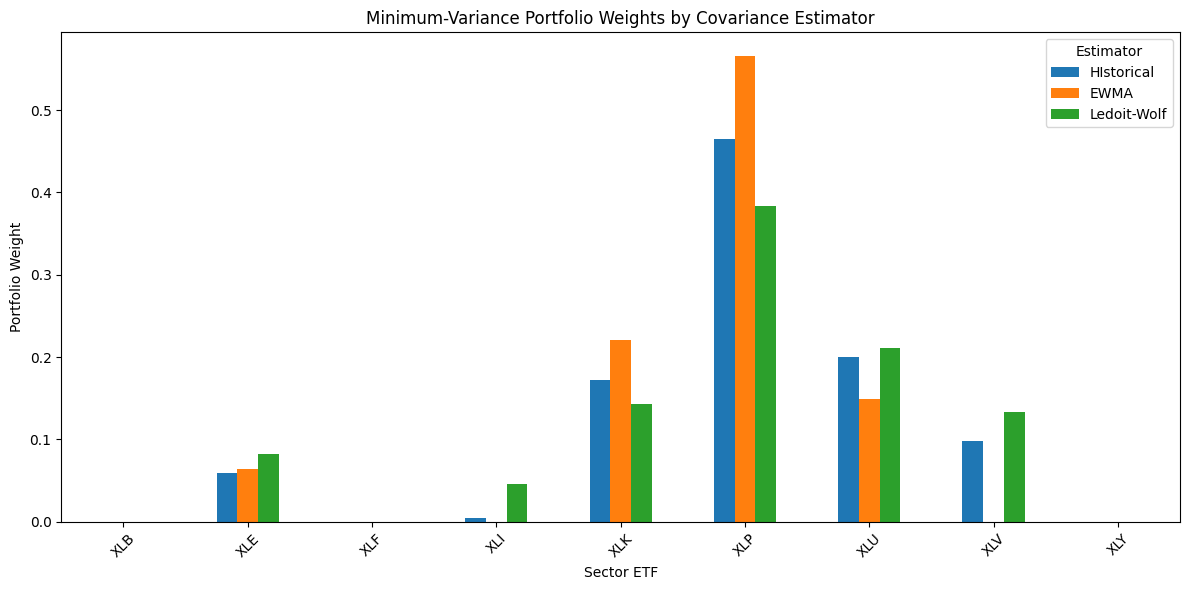

In [155]:
portfolio_weights.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Minimum-Variance Portfolio Weights by Covariance Estimator"
)

plt.xlabel("Sector ETF")
plt.ylabel("Portfolio Weight")
plt.xticks(rotation=45)
plt.legend(title="Estimator")
plt.tight_layout()
plt.show()

In [156]:
def annualised_portfolio_volatility(weights, covariance_matrix):

    daily_variance = portfolio_variance(
        weights,
        np.asarray(covariance_matrix)
    )

    return np.sqrt(
        max(daily_variance, 0.0) * 252
    )

In [157]:
estimated_volatility = pd.Series({
    "Historical": annualised_portfolio_volatility(
        weights_historical,
        cov_last
    ),
    "EWMA": annualised_portfolio_volatility(
        weights_ewma,
        ewma_cov_last
    ),
    "Ledoit-Wolf": annualised_portfolio_volatility(
        weights_shrinkage,
        shrinkage_cov_last
    ),
})

print(
    (estimated_volatility * 100).round(2)
)

Historical     7.84
EWMA           6.11
Ledoit-Wolf    7.81
dtype: float64


In [158]:
def portfolio_concentration(weights):
    return np.sum(np.square(weights))

In [159]:
concentration_comparison = pd.Series({
    "Historical": portfolio_concentration(
        weights_historical
    ),
    "EWMA": portfolio_concentration(
        weights_ewma
    ),
    "Ledoit-Wolf": portfolio_concentration(
        weights_shrinkage
    ),
})

concentration_comparison



,0
Historical,0.298768
EWMA,0.395474
Ledoit-Wolf,0.239171


In [160]:
for name, weights in {
    "Historical": weights_historical,
    "EWMA": weights_ewma,
    "Ledoit-Wolf": weights_shrinkage
}.items():

    print(f"\n{name}")

    print(
        "Weights sum to 1:",
        np.isclose(weights.sum(), 1.0)
    )

    print(
        "Long-only:",
        np.all(weights >= -1-8)
    )

    print(
        "Finite weights:",
        np.all(np.isfinite(weights))
    )


Historical
Weights sum to 1: True
Long-only: True
Finite weights: True

EWMA
Weights sum to 1: True
Long-only: True
Finite weights: True

Ledoit-Wolf
Weights sum to 1: True
Long-only: True
Finite weights: True


In [161]:
equal_weights = np.ones(9) / 9

for name, weights, covariance in [
    ("Historical", weights_historical, cov_last),
    ("EWMA", weights_ewma, ewma_cov_last),
    ("Ledoit-Wolf", weights_shrinkage, shrinkage_cov_last)
]:

    equal_var = portfolio_variance(
        equal_weights,
        covariance.values
    )

    optimised_var = portfolio_variance(
        weights,
        covariance.values
    )

    print(
        name,
        "Optimised variance <= Equal-weight variance:",
        optimised_var <= equal_var + 1e-10
    )

Historical Optimised variance <= Equal-weight variance: True
EWMA Optimised variance <= Equal-weight variance: True
Ledoit-Wolf Optimised variance <= Equal-weight variance: True


In [162]:
portfolio_weights.to_csv(
    "step21_minimum_variance_weights.csv"
)

estimated_volatility.to_csv(
    "step21_estimated_volatility.csv"
)

concentration_comparison.to_csv(
    "step21_portfolio_concentration.csv"
)

### Minimum-Variance Portfolio Optimisation

A long-only, fully invested global minimum-variance portfolio
optimisation procedure was implemented using SciPy's SLSQP solver.

Portfolio variance was minimised subject to weights summing to one
and individual weights being constrained between zero and one.

The optimisation was applied separately to the Historical, EWMA
and Ledoit-Wolf covariance estimates for the nine sector ETFs.

Resulting portfolio weights were compared in terms of allocation,
estimated annualised volatility and weight concentration.

These single-date comparisons are preliminary diagnostics rather
than evidence of out-of-sample superiority. A subsequent walk-forward
evaluation will assess realised portfolio risk, turnover and
stability using information available at each decision date.

In [163]:

import numpy as np
import pandas as pd
from scipy.optimize import minimize, Bounds, LinearConstraint
from sklearn.covariance import LedoitWolf

LOOKBACK = 252
REBALANCE = 21
TRADING_DAYS = 252
COST_BPS = 10

R = sector_returns.sort_index().astype(float).copy()
R = R.dropna()

assert R.shape[1] == 9
assert R.index.is_unique
assert R.index.is_monotonic_increasing
assert np.isfinite(R.to_numpy()).all()
assert len(R) > LOOKBACK + REBALANCE

def get_covariances(window):
    X = window.to_numpy()

    historical = np.cov(X, rowvar=False, ddof=1)

    # EWMA covariance with lambda = 0.94
    decay = 0.94
    centered = X - X.mean(axis=0)
    weights = decay ** np.arange(len(X)-1, -1, -1)
    weights /= weights.sum()

    ewma = (centered * weights[:, None]).T @ centered

    shrinkage = LedoitWolf().fit(X).covariance_

    static_blend = (
        historical + ewma + shrinkage
    ) / 3

    return {
        "Historical": historical,
        "EWMA": ewma,
        "Ledoit-Wolf": shrinkage,
        "Static Blend": static_blend
    }

def optimise_portfolio(cov):

    cov = np.asarray(cov, dtype=float)
    cov = (cov + cov.T) / 2

    n = cov.shape[0]

    # Check covariance matrix
    if not np.isfinite(cov).all():
        raise ValueError("Covariance contains NaN or infinity")

    # Numerical safeguard for tiny negative eigenvalues
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    eigenvalues = np.maximum(eigenvalues, 1e-12)

    cov = (eigenvectors * eigenvalues) @ eigenvectors.T

    # Scale objective for numerical stability
    scale = 1 / max(np.max(np.abs(cov)), 1e-12)

    def objective(w):
        return scale * (w @ cov @ w)

    def gradient(w):
        return 2 * scale * (cov @ w)

    initial_weights = np.ones(n) / n

    constraints = [{
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1,
        "jac": lambda w: np.ones(n)
    }]

    result = minimize(
        objective,
        initial_weights,
        jac=gradient,
        method="SLSQP",
        bounds=[(0, 1)] * n,
        constraints=constraints,
        options={
            "ftol": 1e-9,
            "maxiter": 2000
        }
    )

    if not result.success:
        print("SLSQP failed. Trying trust-constr...")

        result = minimize(
            objective,
            initial_weights,
            jac=gradient,
            hess=lambda w: 2 * scale * cov,
            method="trust-constr",
            bounds=Bounds(
                np.zeros(n),
                np.ones(n)
            ),
            constraints=LinearConstraint(
                np.ones((1, n)),
                [1.0],
                [1.0]
            ),
            options={
                "maxiter": 2000,
                "gtol": 1e-9,
                "xtol": 1e-9,
                "verbose": 0
            }
        )

    if not result.success:
        raise RuntimeError(
            f"Portfolio optimisation failed: {result.message}"
        )

    weights = result.x

    if (
        np.any(weights < -1e-6)
        or np.any(weights > 1 + 1e-6)
        or not np.isclose(weights.sum(), 1, atol=1e-6)
    ):
        raise RuntimeError("Invalid portfolio weights")

    return weights



In [164]:

test_window = R.iloc[:LOOKBACK]

test_covariances = get_covariances(test_window)

for name, cov in test_covariances.items():

    weights = optimise_portfolio(cov)

    print(f"\n{name}")
    print("Weights:", np.round(weights, 4))
    print("Sum:", weights.sum())
    print("Minimum weight:", weights.min())
    print("Portfolio variance:", weights @ cov @ weights)



Historical
Weights: [0.    0.    0.    0.    0.    0.963 0.037 0.    0.   ]
Sum: 1.0
Minimum weight: 0.0
Portfolio variance: 5.802418264919645e-05

EWMA
Weights: [0.     0.     0.     0.     0.     0.5881 0.4119 0.     0.    ]
Sum: 1.0
Minimum weight: 0.0
Portfolio variance: 1.732935491604714e-05

Ledoit-Wolf
Weights: [0.     0.     0.     0.     0.     0.8539 0.0905 0.0556 0.    ]
Sum: 1.0000000000000002
Minimum weight: 0.0
Portfolio variance: 5.925071700685291e-05

Static Blend
Weights: [0.     0.     0.     0.     0.     0.8656 0.1344 0.     0.    ]
Sum: 1.0000000000000004
Minimum weight: 0.0
Portfolio variance: 4.5415195978410574e-05


In [165]:

strategies = [
    "Historical", "EWMA",
    "Ledoit-Wolf", "Static Blend", "Equal Weight"
]

return_log = {s: [] for s in strategies}
turnover_log = {s: [] for s in strategies}
weight_log = {s: [] for s in strategies}

# Track post-drift portfolio weights between rebalances
previous_weights = {s: None for s in strategies}

for t in range(LOOKBACK, len(R), REBALANCE):

    train = R.iloc[t - LOOKBACK:t]
    test = R.iloc[t:t + REBALANCE]

    covariance_models = get_covariances(train)

    targets = {
        name: optimise_portfolio(cov)
        for name, cov in covariance_models.items()
    }

    targets["Equal Weight"] = (
        np.ones(R.shape[1]) / R.shape[1]
    )

    for name, target in targets.items():

        previous = previous_weights[name]

        turnover = (
            0.0 if previous is None
            else np.abs(target - previous).sum()
        )

        cost = turnover * COST_BPS / 10000
        turnover_log[name].append(turnover)
        weight_log[name].append(
            (test.index[0], target.copy())
        )

        # Start with target holdings after rebalance
        holdings = target.copy()
        first_day = True

        for date, row in test.iterrows():

            gross = holdings * (1 + row.to_numpy())
            gross_return = gross.sum() - 1

            # Deduct trading cost on first day
            if first_day:
                net_return = (
                    (1 - cost) * (1 + gross_return) - 1
                )
                first_day = False
            else:
                net_return = gross_return

            return_log[name].append((date, net_return))

            # Allow portfolio weights to drift
            holdings = gross / gross.sum()

        previous_weights[name] = holdings.copy()

backtest_returns = pd.DataFrame({
    name: pd.Series(dict(return_log[name]))
    for name in strategies
}).sort_index()

print(backtest_returns.head())
print(backtest_returns.shape)

assert backtest_returns.notna().all().all()
assert backtest_returns.index.is_unique


            Historical      EWMA  Ledoit-Wolf  Static Blend  Equal Weight
2011-01-04   -0.002452  0.000352    -0.001726     -0.001724     -0.001610
2011-01-05    0.000092 -0.002423    -0.000164     -0.000562      0.003688
2011-01-06   -0.003259 -0.001618    -0.002606     -0.002833     -0.002413
2011-01-07   -0.004832 -0.001583    -0.004113     -0.003988     -0.000899
2011-01-10    0.000460 -0.001838    -0.000066     -0.000139     -0.001252
(3770, 5)


In [166]:

def calculate_metrics(r, turnover):
    r = r.dropna()
    wealth = (1 + r).cumprod()

    annual_vol = r.std() * np.sqrt(252)

    sharpe = (
        r.mean() / r.std() * np.sqrt(252)
        if r.std() > 0 else np.nan
    )

    drawdown = wealth / wealth.cummax() - 1

    return {
        "Realised Volatility": annual_vol,
        "Annualised Return": wealth.iloc[-1] ** (252 / len(r)) - 1,
        "Sharpe (Rf=0)": sharpe,
        "Maximum Drawdown": drawdown.min(),
        "Average Turnover": np.mean(turnover)
    }

results = pd.DataFrame({
    s: calculate_metrics(
        backtest_returns[s],
        turnover_log[s]
    )
    for s in strategies
}).T

display(results.round(4))

print(
    "Lowest realised volatility:",
    results["Realised Volatility"].idxmin()
)


,Realised Volatility,Annualised Return,Sharpe (Rf=0),Maximum Drawdown,Average Turnover
Historical,0.1358,0.0850,0.6690,-0.3457,0.1311
EWMA,0.1339,0.0751,0.6079,-0.2951,0.6765
Ledoit-Wolf,0.1360,0.0904,0.7046,-0.3466,0.1224
Static Blend,0.1332,0.0811,0.6524,-0.3097,0.2903
Equal Weight,0.1654,0.1009,0.6647,-0.3922,0.0240


Lowest realised volatility: Static Blend


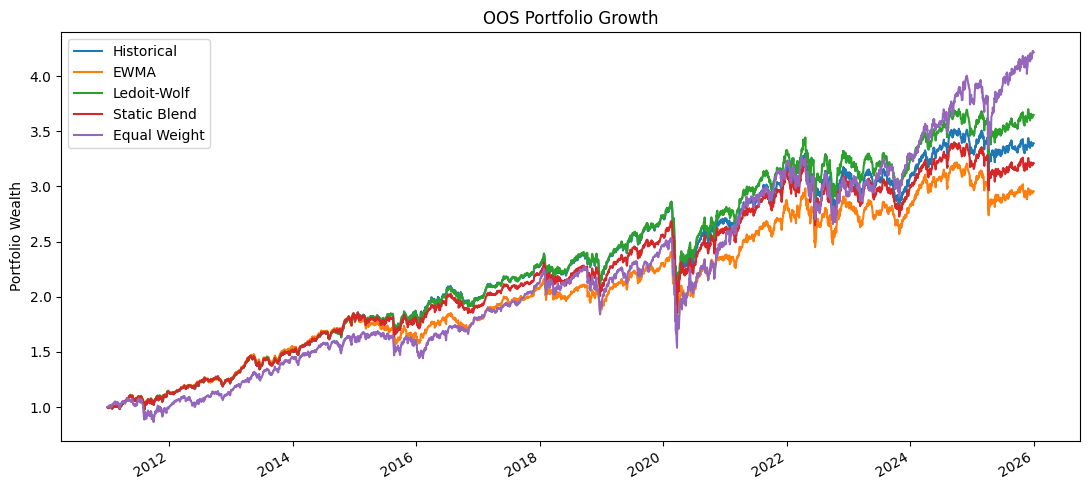

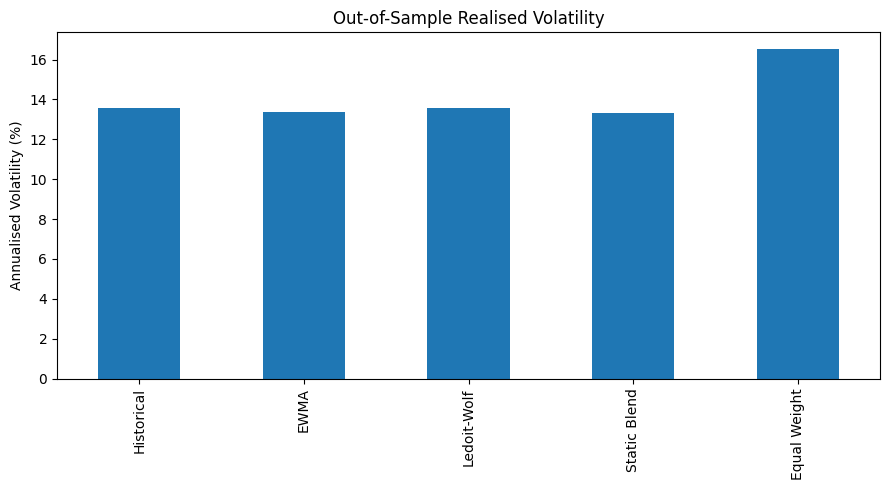

In [167]:

import matplotlib.pyplot as plt

equity = (1 + backtest_returns).cumprod()

equity.plot(figsize=(11, 5), title="OOS Portfolio Growth")
plt.ylabel("Portfolio Wealth")
plt.tight_layout()
plt.savefig("portfolio_growth.png", dpi=200)
plt.show()

(results["Realised Volatility"] * 100).plot(
    kind="bar", figsize=(9, 5),
    title="Out-of-Sample Realised Volatility"
)
plt.ylabel("Annualised Volatility (%)")
plt.tight_layout()
plt.savefig("volatility_comparison.png", dpi=200)
plt.show()

results.to_csv("portfolio_results.csv")
backtest_returns.to_csv("oos_returns.csv")


In [168]:

import numpy as np
import pandas as pd

# Align market indicators to the sector ETF trading calendar
spy = spy_price.reindex(R.index).ffill()
vix = vix.reindex(R.index).ffill()

# SPY daily simple returns
spy_returns = spy.pct_change()

# Construct market-state features
market_features = pd.DataFrame(index=R.index)

market_features["VIX"] = vix

market_features["SPY_21D_VOL"] = (
    spy_returns.rolling(21).std() * np.sqrt(252)
)

market_features["SPY_21D_RETURN"] = (
    spy.pct_change(21)
)

market_features["VIX_5D_CHANGE"] = (
    vix.pct_change(5, fill_method=None)
)

# One-day lag prevents using today's closing values
# to make a decision at the beginning of today
market_features = market_features.shift(1)

display(market_features.tail())
print(market_features.isna().sum())


,VIX,SPY_21D_VOL,SPY_21D_RETURN,VIX_5D_CHANGE
Date,,,,
2025-12-23,14.08,0.105190,0.052601,-0.146667
2025-12-24,14.00,0.101958,0.046982,-0.150485
2025-12-26,13.47,0.091486,0.035425,-0.235528
2025-12-29,13.60,0.087191,0.025673,-0.193835
2025-12-30,14.20,0.086130,0.015011,-0.047619


VIX                1
SPY_21D_VOL       22
SPY_21D_RETURN    22
VIX_5D_CHANGE      6
dtype: int64


In [169]:

assert market_features.index.equals(R.index)

print("Market features:")
print(market_features.columns.tolist())

print("\nAvailable observations:")
print(market_features.dropna().shape)

display(market_features.describe())


Market features:
['VIX', 'SPY_21D_VOL', 'SPY_21D_RETURN', 'VIX_5D_CHANGE']

Available observations:
(4000, 4)


,VIX,SPY_21D_VOL,SPY_21D_RETURN,VIX_5D_CHANGE
count,4021.000000,4000.000000,4000.000000,4016.000000
mean,18.414347,0.147247,0.011996,0.012722
std,6.875271,0.091733,0.042733,0.176769
min,9.140000,0.034205,-0.327513,-0.466691
25%,13.770000,0.092819,-0.007832,-0.085189
50%,16.660000,0.125151,0.017430,-0.011163
75%,21.100000,0.174869,0.036982,0.079236
max,82.690002,0.929687,0.251851,2.129032


In [170]:

def regime_weights(features):

    vix = features["VIX"]
    spy_vol = features["SPY_21D_VOL"]

    # High volatility / stressed market
    if vix >= 25 or spy_vol >= 0.25:
        return np.array([0.15, 0.70, 0.15])

    # Relatively calm market
    return np.array([0.35, 0.20, 0.45])


def adaptive_covariance(covariances, features):

    weights = regime_weights(features)

    matrices = [
        covariances["Historical"],
        covariances["EWMA"],
        covariances["Ledoit-Wolf"]
    ]

    combined = sum(
        weight * matrix
        for weight, matrix in zip(weights, matrices)
    )

    return combined, weights


In [171]:

adaptive_returns = []
adaptive_turnover = []
adaptive_weights = []
regime_records = []

previous_weights = None

for t in range(LOOKBACK, len(R), REBALANCE):

    train = R.iloc[t - LOOKBACK:t]
    test = R.iloc[t:t + REBALANCE]

    if test.empty:
        continue

    # Already lagged by one trading day
    features = market_features.iloc[t]

    if not np.isfinite(features.to_numpy()).all():
        continue

    covariances = get_covariances(train)

    adaptive_cov, expert_weights = adaptive_covariance(
        covariances, features
    )

    target = optimise_portfolio(adaptive_cov)

    turnover = (
        0.0 if previous_weights is None
        else np.abs(target - previous_weights).sum()
    )

    cost = turnover * COST_BPS / 10000

    adaptive_turnover.append(turnover)
    adaptive_weights.append((test.index[0], target.copy()))

    regime_records.append({
        "Date": test.index[0],
        "VIX": features["VIX"],
        "SPY Volatility": features["SPY_21D_VOL"],
        "Historical Weight": expert_weights[0],
        "EWMA Weight": expert_weights[1],
        "Ledoit-Wolf Weight": expert_weights[2]
    })

    holdings = target.copy()
    first_day = True

    for date, row in test.iterrows():

        gross = holdings * (1 + row.to_numpy())
        gross_return = gross.sum() - 1

        if first_day:
            net_return = (1 - cost) * (
                1 + gross_return
            ) - 1
            first_day = False
        else:
            net_return = gross_return

        adaptive_returns.append((date, net_return))

        holdings = gross / gross.sum()

    previous_weights = holdings.copy()

adaptive_series = pd.Series(
    dict(adaptive_returns),
    name="Adaptive Regime"
).sort_index()

regime_df = pd.DataFrame(regime_records)

display(regime_df.head())
print("Adaptive backtest observations:", len(adaptive_series))


,Date,VIX,SPY Volatility,Historical Weight,EWMA Weight,Ledoit-Wolf Weight
0,2011-01-04,17.610001,0.052222,0.35,0.2,0.45
1,2011-02-03,17.299999,0.108339,0.35,0.2,0.45
2,2011-03-07,19.059999,0.132802,0.35,0.2,0.45
3,2011-04-05,17.500000,0.146522,0.35,0.2,0.45
4,2011-05-05,17.080000,0.091460,0.35,0.2,0.45


Adaptive backtest observations: 3770


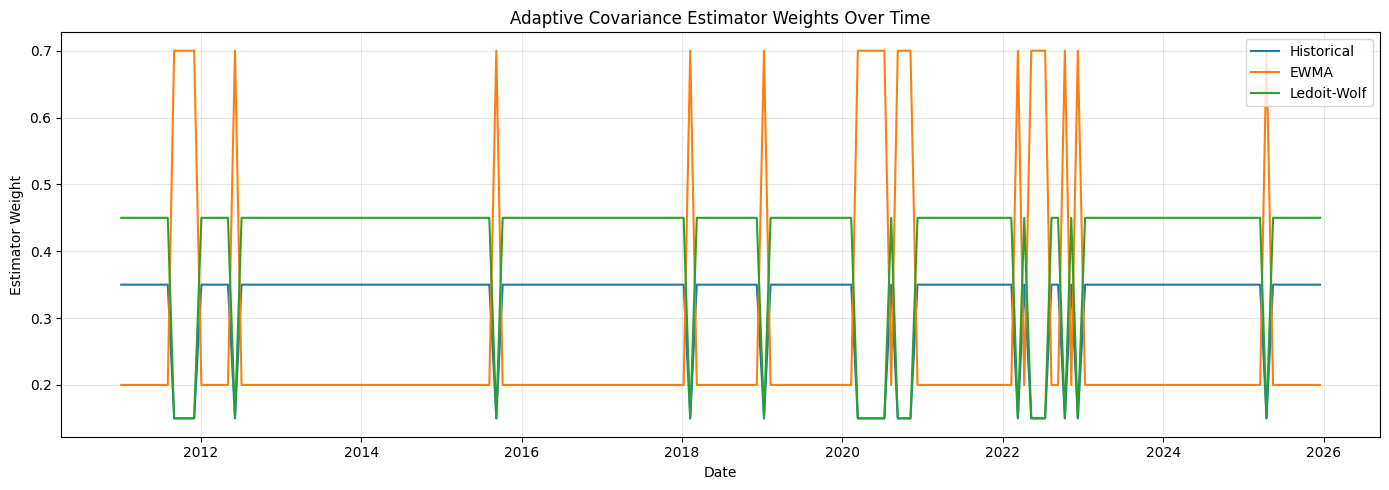

In [172]:
import matplotlib.pyplot as plt

regime_df["Date"] = pd.to_datetime(regime_df["Date"])

plt.figure(figsize=(14, 5))

plt.plot(
    regime_df["Date"],
    regime_df["Historical Weight"],
    label="Historical"
)

plt.plot(
    regime_df["Date"],
    regime_df["EWMA Weight"],
    label="EWMA"
)

plt.plot(
    regime_df["Date"],
    regime_df["Ledoit-Wolf Weight"],
    label="Ledoit-Wolf"
)

plt.title("Adaptive Covariance Estimator Weights Over Time")
plt.xlabel("Date")
plt.ylabel("Estimator Weight")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [173]:

comparison_returns = backtest_returns.join(
    adaptive_series,
    how="inner"
).dropna()

comparison_results = pd.DataFrame({
    name: calculate_metrics(
        comparison_returns[name],
        (
            adaptive_turnover
            if name == "Adaptive Regime"
            else turnover_log[name]
        )
    )
    for name in comparison_returns.columns
}).T

display(comparison_results.round(4))

print(
    "Lowest realised volatility:",
    comparison_results["Realised Volatility"].idxmin()
)


,Realised Volatility,Annualised Return,Sharpe (Rf=0),Maximum Drawdown,Average Turnover
Historical,0.1358,0.0850,0.6690,-0.3457,0.1311
EWMA,0.1339,0.0751,0.6079,-0.2951,0.6765
Ledoit-Wolf,0.1360,0.0904,0.7046,-0.3466,0.1224
Static Blend,0.1332,0.0811,0.6524,-0.3097,0.2903
Equal Weight,0.1654,0.1009,0.6647,-0.3922,0.0240
Adaptive Regime,0.1326,0.0817,0.6592,-0.3029,0.2639


Lowest realised volatility: Adaptive Regime


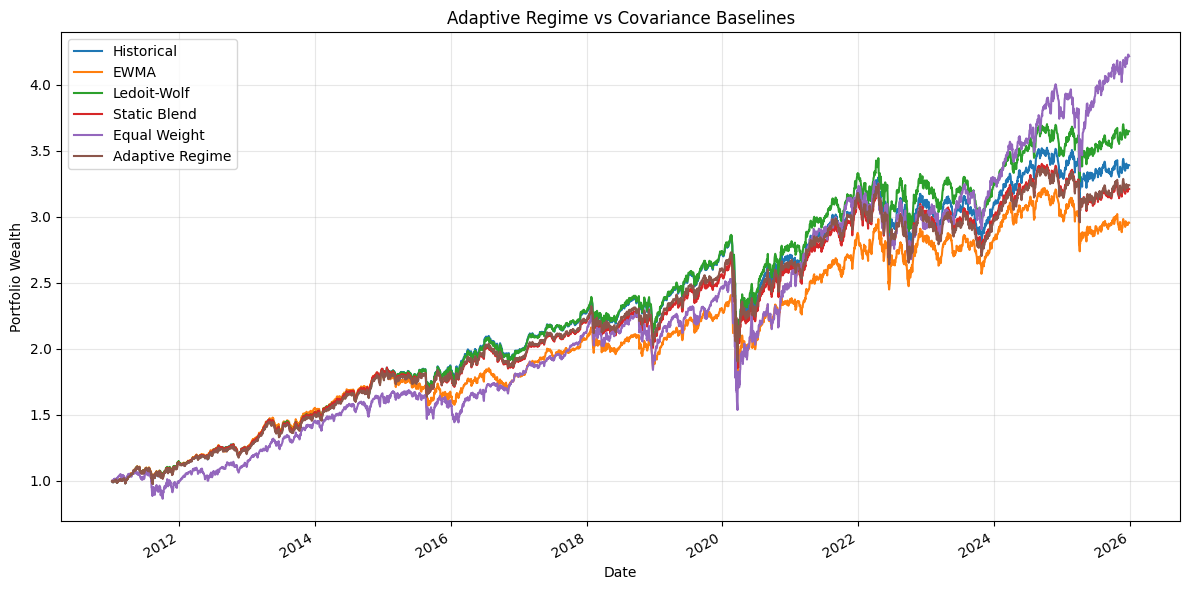

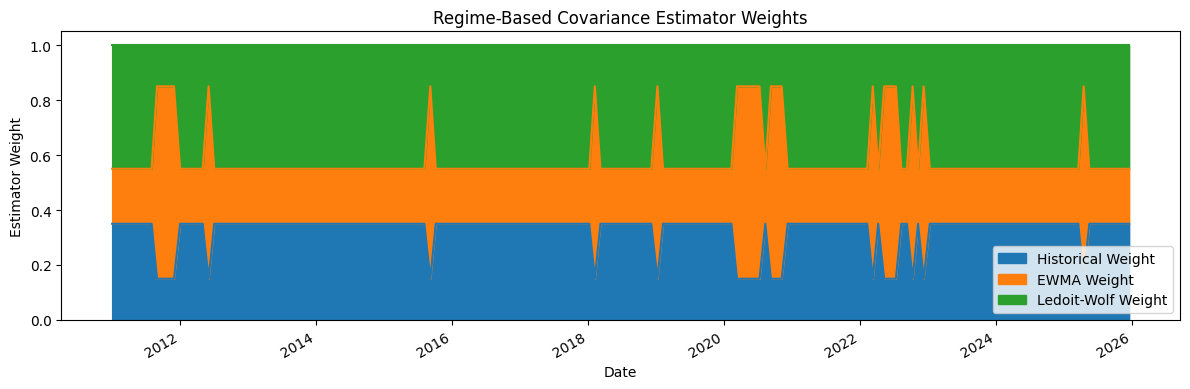

In [174]:

import matplotlib.pyplot as plt

equity = (1 + comparison_returns).cumprod()

equity.plot(figsize=(12, 6), linewidth=1.5)

plt.title("Adaptive Regime vs Covariance Baselines")
plt.ylabel("Portfolio Wealth")
plt.xlabel("Date")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("adaptive_vs_baselines.png", dpi=200)
plt.show()

regime_df.set_index("Date")[
    ["Historical Weight", "EWMA Weight", "Ledoit-Wolf Weight"]
].plot.area(figsize=(12, 4))

plt.title("Regime-Based Covariance Estimator Weights")
plt.ylabel("Estimator Weight")
plt.xlabel("Date")
plt.tight_layout()
plt.savefig("adaptive_estimator_weights.png", dpi=200)
plt.show()

comparison_results.to_csv("adaptive_comparison_results.csv")
regime_df.to_csv("adaptive_regime_history.csv", index=False)


In [175]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
from pathlib import Path

SECTOR_ETFS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
LOOKBACK = 252
REBALANCE = 21
EWMA_LAMBDA = 0.94
COST_RATE = 0.001  # 10 bp per unit of one-way turnover

# EDIT THESE THREE LINES to match existing data objects in your notebook.
# PRICE_SOURCE: DataFrame with the nine ETF adjusted-close prices.
# SPY_SOURCE: Series of SPY adjusted-close prices.
# VIX_SOURCE: Series of VIX closing index levels (e.g., 15–40, NOT 0.15–0.40).
PRICE_SOURCE = prices
SPY_SOURCE = spy_price
VIX_SOURCE = vix


def clean_series(source, name):
    if isinstance(source, pd.DataFrame):
        if source.shape[1] != 1:
            raise ValueError(f"{name} must be a Series or a 1-column DataFrame")
        source = source.iloc[:, 0]
    out = pd.to_numeric(source, errors="coerce").copy()
    out.index = pd.to_datetime(out.index)
    out = out[~out.index.duplicated(keep="last")].sort_index()
    out = out.replace([np.inf, -np.inf], np.nan).dropna()
    if (out <= 0).any():
        raise ValueError(f"{name} contains nonpositive values")
    return out.rename(name)

raw_etf = PRICE_SOURCE.copy()
raw_etf.index = pd.to_datetime(raw_etf.index)
raw_etf = raw_etf[~raw_etf.index.duplicated(keep="last")].sort_index()
assert set(SECTOR_ETFS).issubset(raw_etf.columns), "Missing one or more sector ETFs"
raw_etf = raw_etf.loc[:, SECTOR_ETFS].apply(pd.to_numeric, errors="coerce")
raw_etf = raw_etf.replace([np.inf, -np.inf], np.nan)
raw_etf = raw_etf.mask(raw_etf <= 0)

n_before = len(raw_etf)
prices_clean = raw_etf.dropna(how="any")
print("Price dates dropped for invalid/missing ETF prices:", n_before - len(prices_clean))

assert len(prices_clean) > LOOKBACK + 3 * REBALANCE
assert prices_clean.index.is_monotonic_increasing and prices_clean.index.is_unique

R_simple = prices_clean.pct_change(fill_method=None).dropna(how="any")
R_log = np.log(prices_clean).diff().dropna(how="any")

# The two return conventions agree after conversion.
assert R_simple.index.equals(R_log.index)
assert np.allclose(R_simple.to_numpy(), np.expm1(R_log.to_numpy()), atol=1e-12)
assert np.isfinite(R_simple.to_numpy()).all()
assert (R_simple.to_numpy() > -1).all()
assert R_simple.columns.tolist() == SECTOR_ETFS

spy_prices = clean_series(SPY_SOURCE, "SPY")
vix_levels = clean_series(VIX_SOURCE, "VIX")

print("Return convention: SIMPLE daily returns")
print("ETF return rows:", len(R_simple))
print("Assets:", R_simple.columns.tolist())

Price dates dropped for invalid/missing ETF prices: 0
Return convention: SIMPLE daily returns
ETF return rows: 4022
Assets: ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']


In [176]:
# Reindex from original auxiliary series and only carry forward older observations.
spy_on_etf_dates = spy_prices.reindex(prices_clean.index, method="ffill")
vix_on_etf_dates = vix_levels.reindex(prices_clean.index, method="ffill")

spy_daily = spy_on_etf_dates.pct_change(fill_method=None)

market_features = pd.DataFrame({
    "VIX": vix_on_etf_dates.shift(1),
    "SPY_21D_VOL": spy_daily.rolling(21, min_periods=21).std().shift(1) * np.sqrt(252),
    "SPY_21D_RETURN": spy_on_etf_dates.pct_change(21, fill_method=None).shift(1),
    "VIX_5D_CHANGE": vix_on_etf_dates.pct_change(5, fill_method=None).shift(1),
}, index=prices_clean.index).reindex(R_simple.index)

FEATURE_COLS = ["VIX", "SPY_21D_VOL", "SPY_21D_RETURN", "VIX_5D_CHANGE"]

assert market_features.index.equals(R_simple.index)
if not (market_features["VIX"].dropna().between(5, 100)).all():
    raise ValueError("VIX must be expressed in INDEX POINTS (for example 20, not 0.20)")

print("Point-in-time feature rows:", market_features.dropna().shape[0])
print(market_features.head(5))

Point-in-time feature rows: 4001
                  VIX  SPY_21D_VOL  SPY_21D_RETURN  VIX_5D_CHANGE
Date                                                             
2010-01-05        NaN          NaN             NaN            NaN
2010-01-06  19.350000          NaN             NaN            NaN
2010-01-07  19.160000          NaN             NaN            NaN
2010-01-08  19.059999          NaN             NaN            NaN
2010-01-11  18.129999          NaN             NaN            NaN


In [177]:
def estimate_covariances(window: pd.DataFrame):
    assert window.columns.tolist() == SECTOR_ETFS, "Asset order changed"
    x = window.to_numpy(dtype=np.float64)
    n, p = x.shape
    assert p == len(SECTOR_ETFS) and n >= 60
    assert np.isfinite(x).all()

    historical = np.cov(x, rowvar=False, ddof=1)

    # Newest return gets the highest EWMA weight.
    raw_weights = EWMA_LAMBDA ** np.arange(n - 1, -1, -1, dtype=float)
    weights = raw_weights / raw_weights.sum()
    ewma_mean = (weights[:, None] * x).sum(axis=0)
    centered = x - ewma_mean
    ewma = (weights[:, None] * centered).T @ centered

    lw_model = LedoitWolf(assume_centered=False).fit(x)
    shrinkage = lw_model.covariance_

    result = {
        "Historical": historical,
        "EWMA": ewma,
        "Ledoit-Wolf": shrinkage,
    }

    for name, cov in result.items():
        verify_covariance(cov, name)
    return result


def verify_covariance(cov, label="covariance"):
    a = np.asarray(cov, dtype=np.float64)
    p = len(SECTOR_ETFS)
    assert a.shape == (p, p), f"Wrong covariance shape for {label}"
    assert np.isfinite(a).all(), f"Nonfinite covariance for {label}"
    assert np.allclose(a, a.T, atol=1e-10), f"Non-symmetric covariance: {label}"
    min_eig = np.linalg.eigvalsh((a + a.T) / 2).min()
    assert min_eig >= -1e-10, f"Non-PSD {label}: min eigenvalue={min_eig}"
    return min_eig

# Verify the finite-window EWMA weight definition independently.
a = EWMA_LAMBDA ** np.arange(LOOKBACK - 1, -1, -1)
a /= a.sum()
assert np.isclose(a.sum(), 1.0)
assert a[-1] > a[0]

trial_covs = estimate_covariances(R_simple.iloc[:LOOKBACK])
print("Estimator checks passed:", list(trial_covs))

Estimator checks passed: ['Historical', 'EWMA', 'Ledoit-Wolf']


In [178]:
EXPERT_NAMES = ["Historical", "EWMA", "Ledoit-Wolf"]
STATIC_ALPHA = np.array([1/3, 1/3, 1/3], dtype=float)
CALM_ALPHA = np.array([0.15, 0.20, 0.65], dtype=float)
STRESS_ALPHA = np.array([0.05, 0.65, 0.30], dtype=float)


def validate_expert_weights(alpha):
    alpha = np.asarray(alpha, dtype=float)
    assert alpha.shape == (3,) and np.isfinite(alpha).all()
    assert (alpha >= 0).all() and np.isclose(alpha.sum(), 1.0)


def rule_based_routing(feature_row):
    vix = float(feature_row["VIX"])
    vol = float(feature_row["SPY_21D_VOL"])
    assert np.isfinite(vix) and np.isfinite(vol)
    stressed = (vix >= 25.0) or (vol >= 0.25)
    alpha = STRESS_ALPHA.copy() if stressed else CALM_ALPHA.copy()
    validate_expert_weights(alpha)
    return ("Stressed" if stressed else "Calm"), alpha


def blend_covariances(experts, alpha):
    validate_expert_weights(alpha)
    for name in EXPERT_NAMES:
        verify_covariance(experts[name], name)
    combination = sum(
        alpha[k] * experts[name]
        for k, name in enumerate(EXPERT_NAMES)
    )
    verify_covariance(combination, "blended covariance")
    return combination


def solve_long_only_gmv(cov):
    verify_covariance(cov)
    p = len(SECTOR_ETFS)
    start = np.ones(p) / p
    scaled = np.asarray(cov) * 10000.0

    res = minimize(
        fun=lambda w: float(w @ scaled @ w),
        x0=start,
        jac=lambda w: 2 * scaled @ w,
        method="SLSQP",
        bounds=[(0.0, 1.0)] * p,
        constraints=[{
            "type": "eq",
            "fun": lambda w: float(w.sum() - 1.0),
            "jac": lambda w: np.ones_like(w),
        }],
        options={"ftol": 1e-11, "maxiter": 1000},
    )
    assert res.success, f"GMV solver failed: {res.message}"
    w = np.asarray(res.x)
    assert np.isfinite(w).all()
    assert abs(w.sum() - 1.0) < 1e-6
    assert w.min() >= -1e-8 and w.max() <= 1 + 1e-8
    return np.maximum(w, 0) / np.maximum(w, 0).sum()

for alpha in (STATIC_ALPHA, CALM_ALPHA, STRESS_ALPHA):
    validate_expert_weights(alpha)

print("Routing and GMV solver ready.")

Routing and GMV solver ready.


In [179]:
rebalance_samples = []

# Advance start date until sufficient shifted market features are available.
first_t = next(
    (
        t for t in range(LOOKBACK, len(R_simple) - REBALANCE + 1)
        if np.isfinite(market_features.iloc[t][FEATURE_COLS].to_numpy(dtype=float)).all()
    ),
    None,
)
assert first_t is not None, "No rebalance date with valid point-in-time features"

for t in range(first_t, len(R_simple) - REBALANCE + 1, REBALANCE):
    x = market_features.iloc[t][FEATURE_COLS]
    assert np.isfinite(x.to_numpy(dtype=float)).all(), f"Missing feature at {R_simple.index[t]}"

    history = R_simple.iloc[t - LOOKBACK:t]
    future = R_simple.iloc[t:t + REBALANCE]
    assert len(history) == LOOKBACK and len(future) == REBALANCE
    assert history.index[-1] < future.index[0]
    assert future.columns.tolist() == SECTOR_ETFS

    estimates = estimate_covariances(history)
    regime, regime_alpha = rule_based_routing(x)
    verify_covariance(blend_covariances(estimates, regime_alpha), "regime blended")

    rebalance_samples.append({
        "date": future.index[0],
        "start_pos": t,
        "features": x.to_numpy(dtype=float),
        "covariances": np.stack([estimates[n] for n in EXPERT_NAMES]),
        "regime": regime,
        "regime_alpha": regime_alpha,
        "future_returns": future.to_numpy(dtype=float),
        "future_dates": future.index.copy(),
    })

assert len(rebalance_samples) >= 5, "Too few rebalance samples"
for i in range(1, len(rebalance_samples)):
    assert rebalance_samples[i-1]["future_dates"][-1] < rebalance_samples[i]["future_dates"][0]

print("Rebalances:", len(rebalance_samples))
print("First:", rebalance_samples[0]["date"])
print("Last:", rebalance_samples[-1]["date"])
print("Shapes:", rebalance_samples[0]["features"].shape,
      rebalance_samples[0]["covariances"].shape,
      rebalance_samples[0]["future_returns"].shape)

Rebalances: 179
First: 2011-01-04 00:00:00
Last: 2025-11-13 00:00:00
Shapes: (4,) (3, 9, 9) (21, 9)


In [180]:
STRATEGIES = [
    "Equal Weight", "Historical", "EWMA", "Ledoit-Wolf",
    "Equal Expert Blend", "Rule-Based Adaptive"
]


def get_target_weights(sample, strategy):
    experts = {
        name: sample["covariances"][k]
        for k, name in enumerate(EXPERT_NAMES)
    }

    if strategy == "Equal Weight":
        w = np.ones(len(SECTOR_ETFS)) / len(SECTOR_ETFS)
    elif strategy in EXPERT_NAMES:
        w = solve_long_only_gmv(experts[strategy])
    elif strategy == "Equal Expert Blend":
        w = solve_long_only_gmv(blend_covariances(experts, STATIC_ALPHA))
    elif strategy == "Rule-Based Adaptive":
        w = solve_long_only_gmv(
            blend_covariances(experts, sample["regime_alpha"])
        )
    else:
        raise ValueError(f"Unknown strategy: {strategy}")

    assert np.isfinite(w).all()
    assert np.isclose(w.sum(), 1.0, atol=1e-6)
    assert w.min() >= -1e-8 and w.max() <= 1 + 1e-8
    return w


def backtest_one_strategy(samples, strategy, cost_rate=COST_RATE):
    p = len(SECTOR_ETFS)
    previous_weights = np.zeros(p)  # Cash before first trading date
    daily_rows = []
    trade_rows = []

    for j, sample in enumerate(samples):
        target = get_target_weights(sample, strategy)
        assert sample["future_returns"].shape == (REBALANCE, p)

        turnover = float(np.abs(target - previous_weights).sum())
        trading_cost = cost_rate * turnover
        assert trading_cost < 1.0

        trade_rows.append({
            "Date": sample["date"],
            "Strategy": strategy,
            "Regime": sample["regime"],
            "Turnover": turnover,
            "CostFraction": trading_cost,
            **{f"Weight_{ticker}": weight for ticker, weight in zip(SECTOR_ETFS, target)},
            **{f"Alpha_{name}": val for name, val in zip(EXPERT_NAMES, sample["regime_alpha"])},
        })

        w = target.copy()
        for d, asset_r in zip(sample["future_dates"], sample["future_returns"]):
            assert np.isfinite(asset_r).all() and (asset_r > -1).all()
            gross_portfolio_r = float(w @ asset_r)
            assert gross_portfolio_r > -1

            # Proper SIMPLE return convention: the holdings multiplier is (1 + r).
            daily_net_r = ((1 + gross_portfolio_r) * (1 - trading_cost) - 1)
            daily_rows.append({"Date": d, "Strategy": strategy,
                               "NetSimpleReturn": daily_net_r, "GrossSimpleReturn": gross_portfolio_r})

            holdings_after_return = w * (1 + asset_r)
            w = holdings_after_return / holdings_after_return.sum()
            assert np.isfinite(w).all() and np.isclose(w.sum(), 1, atol=1e-8)
            trading_cost = 0.0  # Charge only once at the start of a holding period

        previous_weights = w.copy()

    return pd.DataFrame(daily_rows), pd.DataFrame(trade_rows)


def run_all_strategies(samples):
    results, trades = [], []
    for strategy in STRATEGIES:
        r, t = backtest_one_strategy(samples, strategy)
        results.append(r)
        trades.append(t)
    return pd.concat(results, ignore_index=True), pd.concat(trades, ignore_index=True)


daily_long, trading_log = run_all_strategies(rebalance_samples)
comparison_returns = daily_long.pivot(
    index="Date", columns="Strategy", values="NetSimpleReturn"
).sort_index()

assert not comparison_returns.isna().any().any()
assert comparison_returns.index.is_unique
assert all(comparison_returns[c].count() == len(comparison_returns) for c in STRATEGIES)

print("Corrected daily returns:", comparison_returns.shape)
print("Rebalance/strategy trade records:", len(trading_log))

Corrected daily returns: (3759, 6)
Rebalance/strategy trade records: 1074


In [181]:
def strategy_metrics(returns, strategy):
    r = pd.Series(returns, dtype=float)
    assert np.isfinite(r.to_numpy()).all() and (r.to_numpy() > -1).all()

    wealth = np.r_[1.0, (1 + r).cumprod().to_numpy()]
    running_max = np.maximum.accumulate(wealth)
    max_drawdown = float(np.min(wealth / running_max - 1.0))

    ann_return = float(wealth[-1] ** (252.0 / len(r)) - 1.0)
    ann_vol = float(r.std(ddof=1) * np.sqrt(252))
    sharpe = float(r.mean() / r.std(ddof=1) * np.sqrt(252)) if r.std(ddof=1) > 0 else np.nan

    trades = trading_log[trading_log["Strategy"] == strategy].sort_values("Date")
    subsequent_turnover = trades["Turnover"].iloc[1:]
    return {
        "Strategy": strategy,
        "Annualised Return": ann_return,
        "Realised Volatility": ann_vol,
        "Sharpe (Rf=0)": sharpe,
        "Maximum Drawdown": max_drawdown,
        "Mean Rebalance Turnover (ex initial)": float(subsequent_turnover.mean()) if len(subsequent_turnover) else np.nan,
        "Total Turnover (inc initial)": float(trades["Turnover"].sum()),
    }

performance = pd.DataFrame([
    strategy_metrics(comparison_returns[s], s) for s in STRATEGIES
]).set_index("Strategy")
display(performance.round(4))

regime_index = pd.Series(
    [s["regime"] for s in rebalance_samples],
    index=pd.DatetimeIndex([s["date"] for s in rebalance_samples]),
    name="Regime",
)
regime_daily = regime_index.reindex(comparison_returns.index, method="ffill")
assert regime_daily.notna().all()

regime_rows = []
for regime in ["Calm", "Stressed"]:
    mask = regime_daily == regime
    for strategy in STRATEGIES:
        r = comparison_returns.loc[mask, strategy]
        if len(r) >= 2:
            regime_rows.append({"Regime": regime, "Strategy": strategy,
                                "Days": len(r), "Annualised Volatility": r.std(ddof=1) * np.sqrt(252)})
regime_performance = pd.DataFrame(regime_rows)
display(regime_performance)

,Annualised Return,Realised Volatility,Sharpe (Rf=0),Maximum Drawdown,Mean Rebalance Turnover (ex initial),Total Turnover (inc initial)
Strategy,,,,,,
Equal Weight,0.1237,0.1651,0.7894,-0.3678,0.0241,5.2873
Historical,0.0999,0.1358,0.7696,-0.3252,0.1325,24.5882
EWMA,0.0886,0.1339,0.7008,-0.2769,0.6881,123.4867
Ledoit-Wolf,0.1054,0.1359,0.8057,-0.3257,0.1235,22.9763
Equal Expert Blend,0.0959,0.1331,0.7549,-0.2906,0.2909,52.7715
Rule-Based Adaptive,0.0971,0.1325,0.7661,-0.2833,0.2607,47.4130


,Regime,Strategy,Days,Annualised Volatility
0,Calm,Equal Weight,3276,0.137776
1,Calm,Historical,3276,0.113602
2,Calm,EWMA,3276,0.114807
3,Calm,Ledoit-Wolf,3276,0.113463
4,Calm,Equal Expert Blend,3276,0.112697
5,Calm,Rule-Based Adaptive,3276,0.112884
6,Stressed,Equal Weight,483,0.288517
7,Stressed,Historical,483,0.236612
8,Stressed,EWMA,483,0.224014
9,Stressed,Ledoit-Wolf,483,0.237232


In [182]:
import json

OUT = Path("AdaptiveCovX_Corrected_PoC")
OUT.mkdir(exist_ok=True)

performance.to_csv(OUT / "performance_corrected.csv")
comparison_returns.to_csv(OUT / "daily_simple_returns_corrected.csv", index_label="Date")
trading_log.to_csv(OUT / "rebalance_weights_and_turnover.csv", index=False)
regime_performance.to_csv(OUT / "regime_performance.csv", index=False)
market_features.to_csv(OUT / "lagged_market_features.csv", index_label="Date")

config = {
    "asset_tickers_in_order": SECTOR_ETFS,
    "asset_prices": "daily adjusted closing prices (user-provided)",
    "return_convention": "simple",
    "covariance_input": "simple daily returns",
    "historical_covariance": "sample ddof=1",
    "ewma_lambda": EWMA_LAMBDA,
    "ewma_convention": "normalised finite-window exponential weights; weighted mean; no unbiased correction",
    "ledoit_wolf": "sklearn.covariance.LedoitWolf, assume_centered=False",
    "lookback_sessions": LOOKBACK,
    "rebalance_sessions": REBALANCE,
    "cost_rate_per_unit_of_turnover": COST_RATE,
    "turnover_definition": "sum of absolute changes in asset weights",
    "initial_purchase_turnover": "included in cost; excluded from average rebalance turnover",
    "vix_threshold_points": 25.0,
    "spy_volatility_threshold_annualised": 0.25,
    "calm_expert_weights": CALM_ALPHA.tolist(),
    "stress_expert_weights": STRESS_ALPHA.tolist(),
    "static_equal_expert_weights": STATIC_ALPHA.tolist(),
    "important_note": "Adaptive policy is a newly specified reproducible benchmark; not reconstruction of missing historical code.",
}
with open(OUT / "run_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Corrected outputs saved:", OUT.resolve())

Corrected outputs saved: /content/AdaptiveCovX_Corrected_PoC


In [183]:
n = len(rebalance_samples)
i_train = int(n * 0.6)
i_val = int(n * 0.8)
assert i_train >= 3 and i_val - i_train >= 1 and n - i_val >= 1

train_samples = rebalance_samples[:i_train]
val_samples = rebalance_samples[i_train:i_val]
test_samples = rebalance_samples[i_val:]

assert train_samples[-1]["future_dates"][-1] < val_samples[0]["date"]
assert val_samples[-1]["future_dates"][-1] < test_samples[0]["date"]

training_X = np.stack([s["features"] for s in train_samples])
train_mean = training_X.mean(axis=0)
train_std = training_X.std(axis=0)
train_std[train_std < 1e-12] = 1.0

for s in rebalance_samples:
    s["x_scaled"] = (s["features"] - train_mean) / train_std

print("Train / Val / Test:", len(train_samples), len(val_samples), len(test_samples))
print("Test begins:", test_samples[0]["date"])
print("Neural input shape:", train_samples[0]["x_scaled"].shape)
print("Expert stack shape:", train_samples[0]["covariances"].shape)
print("Outcome shape:", train_samples[0]["future_returns"].shape)

Train / Val / Test: 107 36 36
Test begins: 2022-12-08 00:00:00
Neural input shape: (4,)
Expert stack shape: (3, 9, 9)
Outcome shape: (21, 9)


In [184]:
%pip install torch

In [185]:
import torch
import torch.nn as nn

torch.manual_seed(42)

if "train_samples" not in globals():
    if "rebalance_samples" not in globals():
        raise RuntimeError(
            "Run the cells that build rebalance_samples before the PyTorch model cell."
        )

    n = len(rebalance_samples)
    i_train = int(n * 0.6)
    i_val = int(n * 0.8)
    if i_train < 3 or i_val - i_train < 1 or n - i_val < 1:
        raise RuntimeError("Not enough rebalance samples for train/validation/test splits.")

    train_samples = rebalance_samples[:i_train]
    val_samples = rebalance_samples[i_train:i_val]
    test_samples = rebalance_samples[i_val:]

    training_X = np.stack([s["features"] for s in train_samples])
    train_mean = training_X.mean(axis=0)
    train_std = training_X.std(axis=0)
    train_std[train_std < 1e-12] = 1.0
    for sample in rebalance_samples:
        sample["x_scaled"] = (sample["features"] - train_mean) / train_std

class AdaptiveCovRouter(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 3), nn.Softmax(dim=-1),
        )

    def forward(self, x):
        return self.net(x)

router = AdaptiveCovRouter().double()
example = train_samples[0]
x = torch.tensor(example["x_scaled"], dtype=torch.float64)
expert_covs = torch.tensor(example["covariances"], dtype=torch.float64)

alpha = router(x)
combined = torch.einsum("k,kij->ij", alpha, expert_covs)

assert bool(torch.all(alpha >= 0))
assert torch.isclose(alpha.sum(), torch.tensor(1., dtype=torch.float64))
assert torch.linalg.eigvalsh(combined).min().item() >= -1e-10

print("Untrained router weights:", alpha.detach().numpy())
print("Combined covariance shape:", tuple(combined.shape))

Untrained router weights: [0.29551608 0.30511485 0.39936907]
Combined covariance shape: (9, 9)


Connecting the neural network to portfolio optimization

In [186]:
import sys

print(sys.executable)

/usr/bin/python3


In [187]:
%pip install cvxpy "cvxpylayers[torch]"

In [188]:
import torch
import cvxpy as cp
from cvxpylayers.torch import CvxpyLayer

print("Everything installed successfully!")

Everything installed successfully!


In [189]:
#step 38.2 - Differentiable GMV optimisation

import cvxpy as cp
from cvxpylayers.torch import CvxpyLayer

if "train_samples" not in globals():
    if "rebalance_samples" not in globals():
        raise RuntimeError(
            "Run the preprocessing cells through the rebalance-sample cell before "
            "creating the differentiable GMV layer."
        )

    if not rebalance_samples:
        raise RuntimeError("rebalance_samples is empty; check the market-data preprocessing cells.")

    n = len(rebalance_samples)
    i_train = int(n * 0.6)
    i_val = int(n * 0.8)
    if i_train < 3 or i_val - i_train < 1 or n - i_val < 1:
        raise RuntimeError("Not enough rebalance samples for train/validation/test splits.")

    train_samples = rebalance_samples[:i_train]
    val_samples = rebalance_samples[i_train:i_val]
    test_samples = rebalance_samples[i_val:]

N_ASSETS = train_samples[0]["covariances"].shape[-1]

print("Number of ETFs:", N_ASSETS)

#portfolio allocation variable
w_var = cp.Variable(N_ASSETS)

#covariance square-root factor
A_param = cp.Parameter((N_ASSETS, N_ASSETS))

#objective: minimise portfolio variance
gmv_problem = cp.Problem(
    cp.Minimize(cp.sum_squares(A_param @ w_var)),
    [
        cp.sum(w_var) == 1,
        w_var >= 0
    ]
)

assert gmv_problem.is_dpp()

gmv_layer = CvxpyLayer(
    gmv_problem, parameters=[A_param], variables=[w_var]
)

print("Differentiable GMV layer created successfully!")

Number of ETFs: 9
Differentiable GMV layer created successfully!


In [190]:
print("Training data exists:", "train_samples" in globals())
print("Neural router exists:", "router" in globals())
print("Rebalance samples exist:", "rebalance_samples" in globals())

Training data exists: True
Neural router exists: True
Rebalance samples exist: True


In [191]:

# STEP 38.3 — Neural portfolio allocation

def neural_gmv_portfolio(sample):

    x = torch.tensor(
        sample["x_scaled"],
        dtype=torch.float64
    )

    expert_covs = torch.tensor(
        sample["covariances"],
        dtype=torch.float64
    )

    # Generate three neural expert weights
    alpha = router(x)

    # Combine the three covariance matrices
    combined_cov = torch.einsum(
        "k,kij->ij",
        alpha,
        expert_covs
    )

    # Numerical scaling and regularisation
    scaled_cov = combined_cov * 10000.0

    scaled_cov = (
        0.5 * (scaled_cov + scaled_cov.T)
        + 1e-4 * torch.eye(
            N_ASSETS,
            dtype=torch.float64
        )
    )

    # Convert covariance to a square-root factor
    L = torch.linalg.cholesky(scaled_cov)
    A_torch = L.T

    # Calculate minimum-variance ETF allocations
    (portfolio_weights,) = gmv_layer(A_torch)

    return portfolio_weights, alpha


In [192]:

# STEP 38.4 — Test neural portfolio allocation

sample = train_samples[0]

portfolio_weights, alpha = neural_gmv_portfolio(sample)

print("Covariance expert weights:")
print(alpha.detach().numpy())

print("\nETF portfolio weights:")

for ticker, weight in zip(
    SECTOR_ETFS,
    portfolio_weights.detach().numpy()
):
    print(f"{ticker}: {weight:.4f}")

print("\nTotal allocation:", portfolio_weights.sum().item())

assert torch.isfinite(portfolio_weights).all()
assert abs(portfolio_weights.sum().item() - 1) < 1e-3
assert portfolio_weights.min().item() >= -1e-3

print("\nStep 38 portfolio checks passed!")


Covariance expert weights:
[0.29551608 0.30511485 0.39936907]

ETF portfolio weights:
XLB: -0.0000
XLE: -0.0000
XLF: -0.0000
XLI: -0.0000
XLK: -0.0000
XLP: 0.8662
XLU: 0.1338
XLV: -0.0000
XLY: -0.0000

Total allocation: 1.0000000009807735

Step 38 portfolio checks passed!
